# Session 7 — Combiner ondelettes, ACP et KNN

**Master 2 Énergie — Diagnostic des systèmes hydrogène · S2-45A / S2-45B**
Université de La Réunion — ENERGY-Lab · Enseignants : Michel Benne, Cédric Damour
**Étudiant : Nicolas NOYON** — `Session_7_NOYON.ipynb`

**Mission.** Deux classifieurs sont construits sur les **mêmes** fenêtres de courant d'un électrolyseur PEM :

- **Branche A** : courant → DWT db4 (5 niveaux) → 5 énergies relatives des détails (RWE) → KNN ($k = 4$) ;
- **Branche B** : courant → DWT → RWE → **ACP** (3 premiers scores) → KNN ($k = 4$).

Le découpage apprentissage/validation et la règle des quatre voisins restent fixes : seule la représentation change. La conclusion distingue **compression des caractéristiques** et **identification physique du défaut**.

| Bloc | Section | Contenu |
|---|---|---|
| A | 1 — A1 | Du système physique à la comparaison |
| A | 2 — A2 | Mêmes fenêtres et étiquettes : chargement, contrôles, tranche S2-45 |
| A | 3 — A3 | De chaque fenêtre à cinq caractéristiques (`extraire_RWE`) |
| A | 4 — A4 | KNN de la branche A et matrices de confusion |
| A | 5 — A5 | Bilan de 15 minutes |
| B | 6 — B1 | ACP d'un espace contraint (rang ≤ 4) |
| B | 7 — B2 | Choix de la dimension : seuil 99,90 % ou q = 3 |
| B | 8 — B3 | KNN réduit (branche B) et point de reprise 3 h + 1 h |
| B | 9 — B4 | Comparer les prédictions (statistiques / A / B) |
| B | 10 — B5 | Invariants, sensibilité et conclusion diagnostique |
| B | 11 — B6 | Synthèse, quiz et auto-évaluation |
| + | 12 — C1 à C4 | Analyse complémentaire : point de fonctionnement et séries (pour le rapport) |

> **Exécution.** Dans Colab : *Exécution → Tout exécuter*. La cellule A2.1 cherche les quatre fichiers MAT dans le dossier courant puis dans Google Drive ; s'ils sont introuvables, une fenêtre de téléversement s'ouvre. Aucun tirage aléatoire n'intervient : une nouvelle exécution redonne exactement les mêmes résultats.
> **Avant la remise : *Exécution → Redémarrer la session et tout exécuter*.**

## 0. Préparation

La première cellule importe les bibliothèques et affiche leurs versions (condition de reproductibilité). PyWavelets (`pywt`) n'étant pas toujours présent dans Colab, il est installé automatiquement s'il manque. La seconde cellule regroupe **toutes** les conventions fixées de la comparaison.

In [1]:
# =============================================================================
# 0.1  Imports et versions
# -----------------------------------------------------------------------------
#  numpy / pandas      : calcul matriciel et tableaux de résultats
#  scipy.io.loadmat    : lecture des fichiers MATLAB (.mat)
#  pywt (PyWavelets)   : transformée en ondelettes discrète (DWT)
#  scikit-learn        : ACP (PCA), KNN, matrices de confusion
#  joblib              : sauvegarde du point de reprise (repère 3 h + 1 h)
# =============================================================================
import sys, platform, unicodedata
from datetime import datetime
from math import floor, sqrt
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy.io import loadmat
from IPython.display import display, Markdown

try:
    import pywt
except ImportError:                               # PyWavelets absent : installation puis import
    import subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "PyWavelets"])
    import pywt

import sklearn
import joblib
from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, pairwise_distances

pd.set_option("display.precision", 4)
pd.set_option("display.width", 140)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

pd.Series({
    "Python": platform.python_version(),
    "NumPy": np.__version__,
    "SciPy": scipy.__version__,
    "PyWavelets": pywt.__version__,
    "scikit-learn": sklearn.__version__,
    "pandas": pd.__version__,
    "Matplotlib": matplotlib.__version__,
    "date d'exécution": datetime.now().strftime("%Y-%m-%d %H:%M"),
}, name="version").to_frame()

,version
Python,3.13.18
NumPy,2.5.3
SciPy,1.18.1
PyWavelets,1.8.0
scikit-learn,1.9.1
pandas,3.0.5
Matplotlib,3.11.2
date d'exécution,2026-11-10 10:17


In [2]:
# =============================================================================
# 0.2  Conventions FIXÉES pour toute la comparaison (ne pas modifier en cours de route)
# =============================================================================
FS = 10.0                                  # fréquence d'échantillonnage indiquée par la source (Hz)
LONGUEUR_BRUTE = 1000                      # points par fenêtre brute (100 s)
N_COTE = floor(sqrt(LONGUEUR_BRUTE))       # N = ⌊√1000⌋ = 31 (longueur carrée historique)
DEBUT, FIN = 1, N_COTE * N_COTE + 1        # tranche S2-45 : x[1 : N*N+1] -> indices 1 à 961
ONDELETTE, NIVEAU = "db4", 5               # décomposition db4 à cinq niveaux
K_VOISINS = 4                              # règle des quatre voisins
NBR_COMPOSANTE_CONSERVE = 3                # q fixé par le code source (branche B)
SEUIL_VARIANCE = 0.9990                    # consigne source : H_q > 99,90 %
CLASSES = {0: "Fonctionnement nominal", 1: "Défaut pompe"}
COULEURS = {0: "tab:blue", 1: "tab:red"}

def fr(valeur, decimales=2):
    """Nombre au format français (virgule décimale) pour les textes générés."""
    return f"{valeur:.{decimales}f}".replace(".", ",")

def md(texte):
    """Affiche un texte Markdown construit à partir des résultats calculés."""
    display(Markdown(texte))

pd.DataFrame({"valeur": {
    "Lignes et étiquettes": "384 apprentissage / 96 validation (découpage de la session 4) ; 0 = nominal, 1 = défaut pompe",
    "Tranche temporelle": f"x[{DEBUT}:{FIN}] -> indices {DEBUT} à {FIN - 1} ({FIN - DEBUT} points)",
    "Décomposition": f"{ONDELETTE}, {NIVEAU} niveaux, extension par défaut de PyWavelets ('symmetric')",
    "Reconstruction des détails": f"pywt.upcoef('d', cDj, '{ONDELETTE}', level=j, take=961), puis ordre inversé -> D1…D5",
    "Caractéristiques (A)": "r_j = E_j / (E_1 + … + E_5), j = 1…5 (A5 exclue du dénominateur)",
    "ACP (B)": f"centrage seul (ni standardisation ni blanchiment), apprise sur l'apprentissage, q = {NBR_COMPOSANTE_CONSERVE}",
    "Classifieur (A, B et référence)": f"KNN k = {K_VOISINS}, distance euclidienne (minkowski, p = 2), votes uniformes",
}}).rename_axis("réglage")

,valeur
réglage,
Lignes et étiquettes,384 apprentissage / 96 validation (découpage d...
Tranche temporelle,x[1:962] -> indices 1 à 961 (961 points)
Décomposition,"db4, 5 niveaux, extension par défaut de PyWave..."
Reconstruction des détails,"pywt.upcoef('d', cDj, 'db4', level=j, take=961..."
Caractéristiques (A),"r_j = E_j / (E_1 + … + E_5), j = 1…5 (A5 exclu..."
ACP (B),centrage seul (ni standardisation ni blanchime...
"Classifieur (A, B et référence)","KNN k = 4, distance euclidienne (minkowski, p ..."


## 1. A1 — Du système physique à la comparaison

### Chaîne phénomène → mesure → caractéristique → modèle → décision → action

| Étape | Dans cette étude |
|---|---|
| **Phénomène** | Une perturbation liée à la pompe (circuit d'eau) peut modifier le débit, l'hydratation de la membrane, la température ou le régime de l'électrolyseur PEM. |
| **Mesure** | Courant de l'électrolyseur échantillonné à 10 Hz, fenêtres de 1000 points (100 s). |
| **Caractéristique** | 5 énergies relatives des détails db4 D1…D5 (RWE), calculées sur la tranche S2-45 de 961 points. |
| **Modèle** | A : KNN ($k=4$) sur les 5 RWE. B : ACP apprise sur l'apprentissage, 3 premiers scores, puis KNN ($k=4$). |
| **Décision** | Classe prédite : 0 = fonctionnement nominal, 1 = défaut pompe. |
| **Action** | Alarme puis **vérification** (débit et pression d'eau, température, inspection de la pompe) avant tout arrêt ou maintenance. |

Le passage phénomène → mesure n'est pas inversible : le même courant peut aussi varier avec la **consigne** (point de fonctionnement) ou avec le **capteur**. Le corpus fournit des **étiquettes**, pas une expérience d'identification causale ; les énergies par échelle doivent donc être lues avec le contexte physique.

### Quatre réglages fixes de la comparaison

1. **Mêmes lignes, mêmes étiquettes** : 384 fenêtres d'apprentissage et 96 de validation (découpage hérité de la session 4).
2. **Même tranche temporelle** : `x[1:962]` (indices 1 à 961) pour toutes les représentations, y compris la référence statistique.
3. **Même décomposition** : db4 à cinq niveaux, même convention de reconstruction (`upcoef`, `take = 961`), même ordre D1 → D5.
4. **Même classifieur** : KNN à $k = 4$, distance euclidienne, votes uniformes.

Entre A et B, **seul** change le passage par l'ACP : c'est le changement de représentation étudié.

### Deux métadonnées expérimentales absentes

- **Unité et étalonnage de la mesure de courant** : capteur, gain, filtrage anti-repliement de la chaîne d'acquisition.
- **Conditions de fonctionnement et nature du défaut** : consigne de courant ou de tension, température, débit et pression d'eau, sévérité et mode de création du défaut pompe.

(Il manque aussi les **identifiants d'essai** et les dates, indispensables pour séparer apprentissage et validation *par essai*.)

### Partie non supervisée, partie supervisée

- **Sans étiquettes** : la DWT et les RWE (transformation déterministe, rien n'est appris) ; l'**ACP**, qui apprend une moyenne et des directions sur `X_train` **sans** utiliser `Y_train`.
- **Avec étiquettes** : le **KNN**, qui mémorise des exemples étiquetés, et l'**évaluation**, qui compare les prédictions aux étiquettes de validation.

> **Remarque bibliographique.** Kim et Tak [1] motivent l'analyse en ondelettes de la **tension** de piles **PEMFC** (ondelette db3). Leur étude ne valide pas ce classifieur **db4** sur le **courant** d'un **électrolyseur** : le transfert PEMFC → PEMWE reste une hypothèse à vérifier.

## 2. A2 — Préparer les mêmes fenêtres et étiquettes

Les quatre fichiers MAT conservent leurs noms d'origine (fiche de la session 5) ; les clés sont données dans le même ordre :

| Fichier | Clé MAT | Contenu attendu |
|---|---|---|
| `PEM_Entrees_Apprentissage.mat` | `Entrees_signal_apprentissage` | 384 fenêtres × 1000 points |
| `PEM_Sorties_Apprentissage.mat` | `Sorties_apprentissage_EPEM` | 384 étiquettes (cellules MATLAB) |
| `PEM_Entrees_Validation.mat` | `Entrees_signal_validation` | 96 fenêtres × 1000 points |
| `PEM_Sorties_Validation.mat` | `Sorties_validation_EPEM` | 96 étiquettes |

**Recherche des fichiers.** La cellule A2.1 regarde d'abord le dossier courant (fichiers téléversés via le panneau *Fichiers* de Colab), puis monte Google Drive et cherche sous `REPERTOIRE` (chemin de la fiche), puis dans tout `MyDrive`. Si **plusieurs** dossiers contiennent les quatre fichiers, la cellule s'arrête : renseigner alors `DOSSIER_DONNEES` explicitement. Si rien n'est trouvé, une fenêtre de téléversement s'ouvre.

In [3]:
# =============================================================================
# A2.1  Localiser les quatre fichiers MAT (dossier courant, Drive ou téléversement)
# =============================================================================
REPERTOIRE = Path("/content/drive/MyDrive/MiTeach/M2_H2_Diagnostic/_Notebook")   # chemin de la fiche
DOSSIER_DONNEES = None     # si plusieurs copies : DOSSIER_DONNEES = Path("/content/drive/MyDrive/...")

FICHIERS = {               # rôle : (nom d'origine du fichier, clé MAT attendue)
    "X_train": ("PEM_Entrees_Apprentissage.mat", "Entrees_signal_apprentissage"),
    "Y_train": ("PEM_Sorties_Apprentissage.mat", "Sorties_apprentissage_EPEM"),
    "X_test":  ("PEM_Entrees_Validation.mat",    "Entrees_signal_validation"),
    "Y_test":  ("PEM_Sorties_Validation.mat",    "Sorties_validation_EPEM"),
}

try:                                        # sommes-nous dans Google Colab ?
    from google.colab import drive, files as colab_files
    EN_COLAB = True
except ImportError:
    EN_COLAB = False

def _simplifier(nom):
    """'PEM_Entrees_Apprentissage.mat' -> 'pementreesapprentissagemat' (comparaison tolérante)."""
    return "".join(c for c in nom.lower() if c.isalnum())

ROLE_PAR_NOM = {_simplifier(nom): role for role, (nom, _) in FICHIERS.items()}

def dossiers_complets(racine, recursif):
    """Dossiers situés sous `racine` qui contiennent les QUATRE fichiers attendus."""
    racine = Path(racine)
    if not racine.is_dir():
        return {}
    motifs = ["**/*.mat"] if recursif else ["*.mat", "*/*.mat"]     # non récursif : deux niveaux
    par_dossier = {}
    for motif in motifs:
        for chemin in racine.glob(motif):
            role = ROLE_PAR_NOM.get(_simplifier(chemin.name))
            if role:
                par_dossier.setdefault(chemin.parent.resolve(), {})[role] = chemin.resolve()
    return {d: r for d, r in par_dossier.items() if len(r) == len(FICHIERS)}

def monter_drive():
    if EN_COLAB and not Path("/content/drive/MyDrive").exists():
        drive.mount("/content/drive")

# Ordre de recherche : du plus précis au plus large ; arrêt au premier succès.
if DOSSIER_DONNEES is not None:
    etapes = [("DOSSIER_DONNEES", Path(DOSSIER_DONNEES), False)]
else:
    etapes = [("dossier courant / fichiers téléversés", Path.cwd(), False)]
    if EN_COLAB:
        etapes += [("REPERTOIRE de la fiche", REPERTOIRE, True),
                   ("tout MyDrive (peut prendre un moment)", Path("/content/drive/MyDrive"), True)]

trouves = {}
for description, racine, recursif in etapes:
    if str(racine).startswith("/content/drive"):
        monter_drive()
    print(f"Recherche : {description} -> {racine}")
    trouves = dossiers_complets(racine, recursif)
    if trouves:
        break

if not trouves and EN_COLAB and DOSSIER_DONNEES is None:
    print("\nFichiers introuvables : sélectionner les 4 fichiers .mat dans la fenêtre ci-dessous.")
    colab_files.upload()                   # enregistre les fichiers dans le dossier courant (/content)
    trouves = dossiers_complets(Path.cwd(), False)

if not trouves:
    raise FileNotFoundError("Les 4 fichiers MAT sont introuvables : vérifier leur emplacement "
                            "ou renseigner DOSSIER_DONNEES.")
if len(trouves) > 1:
    raise RuntimeError("Plusieurs copies complètes trouvées :\n"
                       + "\n".join(f"  - {d}" for d in trouves)
                       + "\n=> renseigner DOSSIER_DONNEES avec le dossier choisi, puis relancer.")

DOSSIER_UTILISE, CHEMINS = next(iter(trouves.items()))
print("\nDossier utilisé :", DOSSIER_UTILISE)

Recherche : dossier courant / fichiers téléversés -> /content

Dossier utilisé : /content


In [4]:
# =============================================================================
# A2.2  Charger et inspecter : chemins, clés, types, dimensions
# =============================================================================
def charger_variable(chemin, cle_attendue):
    """Charge un fichier MAT ; renvoie (tableau, clé utilisée, liste des clés utiles)."""
    contenu = loadmat(chemin)                                  # dictionnaire {clé: tableau}
    cles = [k for k in contenu if not k.startswith("__")]      # on écarte __header__, __version__...
    if cle_attendue in contenu:
        cle = cle_attendue
    elif len(cles) == 1:                                       # une seule variable, nom différent
        cle = cles[0]
        print(f"[info] {chemin.name} : clé '{cle_attendue}' absente, utilisation de '{cle}'")
    else:
        raise KeyError(f"{chemin.name} : clé '{cle_attendue}' absente ; clés disponibles : {cles}")
    return contenu[cle], cle, cles

ORIGINAUX = {}            # tableaux tels que lus : on ne les modifie jamais
lignes_inspection = []
for role, (nom, cle_attendue) in FICHIERS.items():
    valeur, cle, cles = charger_variable(CHEMINS[role], cle_attendue)
    ORIGINAUX[role] = valeur
    lignes_inspection.append({"rôle": role, "chemin": str(CHEMINS[role]), "clés": ", ".join(cles),
                              "clé utilisée": cle, "type": type(valeur).__name__,
                              "dtype": str(valeur.dtype), "shape": valeur.shape})
pd.DataFrame(lignes_inspection).set_index("rôle")

,chemin,clés,clé utilisée,type,dtype,shape
rôle,,,,,,
X_train,/content/PEM_Entrees_Apprentissage.mat,Entrees_signal_apprentissage,Entrees_signal_apprentissage,ndarray,float64,"(384, 1000)"
Y_train,/content/PEM_Sorties_Apprentissage.mat,Sorties_apprentissage_EPEM,Sorties_apprentissage_EPEM,ndarray,object,"(384, 1)"
X_test,/content/PEM_Entrees_Validation.mat,Entrees_signal_validation,Entrees_signal_validation,ndarray,float64,"(96, 1000)"
Y_test,/content/PEM_Sorties_Validation.mat,Sorties_validation_EPEM,Sorties_validation_EPEM,ndarray,object,"(96, 1)"


In [5]:
# =============================================================================
# A2.3  Signaux en float (copies) et étiquettes MATLAB -> entiers 0/1 à une dimension
# =============================================================================
def preparer_signaux(tableau, nom):
    """Copie en float, une fenêtre par ligne ; l'original reste intact dans ORIGINAUX."""
    X = np.array(tableau, dtype=float, copy=True)
    if X.ndim != 2:
        raise ValueError(f"{nom} : tableau 2D attendu, reçu {X.shape}")
    if X.shape[1] != LONGUEUR_BRUTE and X.shape[0] == LONGUEUR_BRUTE:
        print(f"[info] {nom} rangé en colonnes {X.shape} : transposition (une fenêtre par ligne)")
        X = X.T
    if X.shape[1] != LONGUEUR_BRUTE:
        raise ValueError(f"{nom} : {LONGUEUR_BRUTE} points par fenêtre attendus, reçu {X.shape}")
    return X

CORRESPONDANCE = {"fonctionnement nominal": 0, "defaut pompe": 1}

def _normaliser(texte):
    """'Fonctionnement_nominal ' -> 'fonctionnement nominal' ; 'Défaut pompe' -> 'defaut pompe'."""
    texte = unicodedata.normalize("NFKD", str(texte)).encode("ascii", "ignore").decode()
    return " ".join(texte.replace("_", " ").lower().split())

def aplatir_cellules(objet):
    """Parcourt récursivement un tableau MATLAB lu par loadmat (une cellule = tableau d'objets)
    et renvoie la liste de ses feuilles (chaînes ou nombres), dans l'ordre des lignes."""
    feuilles = []
    def visiter(o):
        if isinstance(o, np.ndarray):
            if o.dtype == object:                  # cellule : on descend dans chaque élément
                for element in o.flat:
                    visiter(element)
            elif o.dtype.kind in "US":             # texte : une chaîne par élément
                feuilles.extend(str(s) for s in o.flat)
            else:                                  # nombres
                feuilles.extend(o.flat)
        else:
            feuilles.append(o)
    visiter(objet)
    return feuilles

def etiquettes_en_entiers(tableau, n_attendu, nom):
    feuilles = aplatir_cellules(tableau)
    if len(feuilles) != n_attendu:
        raise ValueError(f"{nom} : {len(feuilles)} étiquettes pour {n_attendu} fenêtres")
    if all(isinstance(f, str) for f in feuilles):
        textes = [_normaliser(f) for f in feuilles]
        inconnues = sorted(set(textes) - set(CORRESPONDANCE))
        if inconnues:
            raise ValueError(f"{nom} : étiquettes inconnues {inconnues}")
        return np.array([CORRESPONDANCE[t] for t in textes], dtype=int)
    valeurs = np.asarray(feuilles, dtype=float)
    if not set(np.unique(valeurs)) <= {0.0, 1.0}:
        raise ValueError(f"{nom} : codes {np.unique(valeurs)} -> correspondance à définir explicitement")
    return valeurs.astype(int)

X_train_brut = preparer_signaux(ORIGINAUX["X_train"], "X_train")
X_test_brut  = preparer_signaux(ORIGINAUX["X_test"],  "X_test")
Y_train = etiquettes_en_entiers(ORIGINAUX["Y_train"], X_train_brut.shape[0], "Y_train")
Y_test  = etiquettes_en_entiers(ORIGINAUX["Y_test"],  X_test_brut.shape[0],  "Y_test")

print("Exemple de cellule brute     :", repr(np.asarray(ORIGINAUX["Y_train"], dtype=object).flat[0]))
print("Étiquettes converties        :", Y_train[:10], "...")
print("Y_train :", Y_train.shape, Y_train.dtype, "| Y_test :", Y_test.shape, Y_test.dtype)

Exemple de cellule brute     : array(['Fonctionnement_nominal'], dtype='<U22')
Étiquettes converties        : [0 0 0 0 0 0 0 0 0 1] ...
Y_train : (384,) int64 | Y_test : (96,) int64


In [6]:
# =============================================================================
# A2.4  Contrôles : dimensions, valeurs finies, effectifs des classes
# =============================================================================
assert X_train_brut.shape == (384, LONGUEUR_BRUTE) and X_test_brut.shape == (96, LONGUEUR_BRUTE)
assert np.isfinite(X_train_brut).all() and np.isfinite(X_test_brut).all(), "valeurs non finies"
assert Y_train.shape == (len(X_train_brut),) and Y_test.shape == (len(X_test_brut),)

display(pd.DataFrame({
    "apprentissage": [X_train_brut.shape, bool(np.isfinite(X_train_brut).all()), Y_train.shape, str(Y_train.dtype)],
    "validation":    [X_test_brut.shape,  bool(np.isfinite(X_test_brut).all()),  Y_test.shape,  str(Y_test.dtype)],
}, index=["signaux (fenêtres, points)", "toutes les valeurs finies", "étiquettes", "type des étiquettes"]))

effectifs = pd.DataFrame({
    "apprentissage": np.bincount(Y_train, minlength=2),
    "validation": np.bincount(Y_test, minlength=2),
    "attendu (fiche S5)": ["288 / 72", "96 / 24"],
}, index=[f"{k} = {v}" for k, v in CLASSES.items()])
display(effectifs)
if list(np.bincount(Y_train)) != [288, 96] or list(np.bincount(Y_test)) != [72, 24]:
    print("ATTENTION : effectifs différents de ceux annoncés en session 5 -> vérifier les fichiers.")

,apprentissage,validation
"signaux (fenêtres, points)","(384, 1000)","(96, 1000)"
toutes les valeurs finies,True,True
étiquettes,"(384,)","(96,)"
type des étiquettes,int64,int64


,apprentissage,validation,attendu (fiche S5)
0 = Fonctionnement nominal,288,72,288 / 72
1 = Défaut pompe,96,24,96 / 24


In [7]:
# =============================================================================
# A2.5  Tranche propre aux sources S2-45 : x[1 : N*N + 1]  (indices 1 à 961)
# =============================================================================
X_train_cond = X_train_brut[:, DEBUT:FIN].copy()      # (384, 961)
X_test_cond  = X_test_brut[:,  DEBUT:FIN].copy()      # (96, 961)
M = X_train_cond.shape[1]
assert M == N_COTE ** 2 == 961 and X_test_cond.shape == (96, M)

t_brut = np.arange(LONGUEUR_BRUTE) / FS               # instant d'origine de l'échantillon n : t = n / fs
pd.Series({
    "N = ⌊√1000⌋": N_COTE,
    "indices Python conservés": f"{DEBUT} à {FIN - 1}",
    "points conservés M": M,
    "points écartés": f"indice 0 et indices {FIN} à {LONGUEUR_BRUTE - 1} ({LONGUEUR_BRUTE - M} points)",
    "premier instant conservé (s)": round(t_brut[DEBUT], 3),
    "dernier instant conservé (s)": round(t_brut[FIN - 1], 3),
    "écart premier → dernier (s)": round(t_brut[FIN - 1] - t_brut[DEBUT], 3),
    "durée retenue M / fs (s)": M / FS,
    "fenêtre brute": f"t = 0 à {t_brut[-1]:.1f} s, durée {LONGUEUR_BRUTE / FS:.0f} s",
}, name="valeur").to_frame()

,valeur
N = ⌊√1000⌋,31
indices Python conservés,1 à 961
points conservés M,961
points écartés,indice 0 et indices 962 à 999 (39 points)
premier instant conservé (s),0.1
dernier instant conservé (s),96.1
écart premier → dernier (s),96.0
durée retenue M / fs (s),96.1
fenêtre brute,"t = 0 à 99.9 s, durée 100 s"


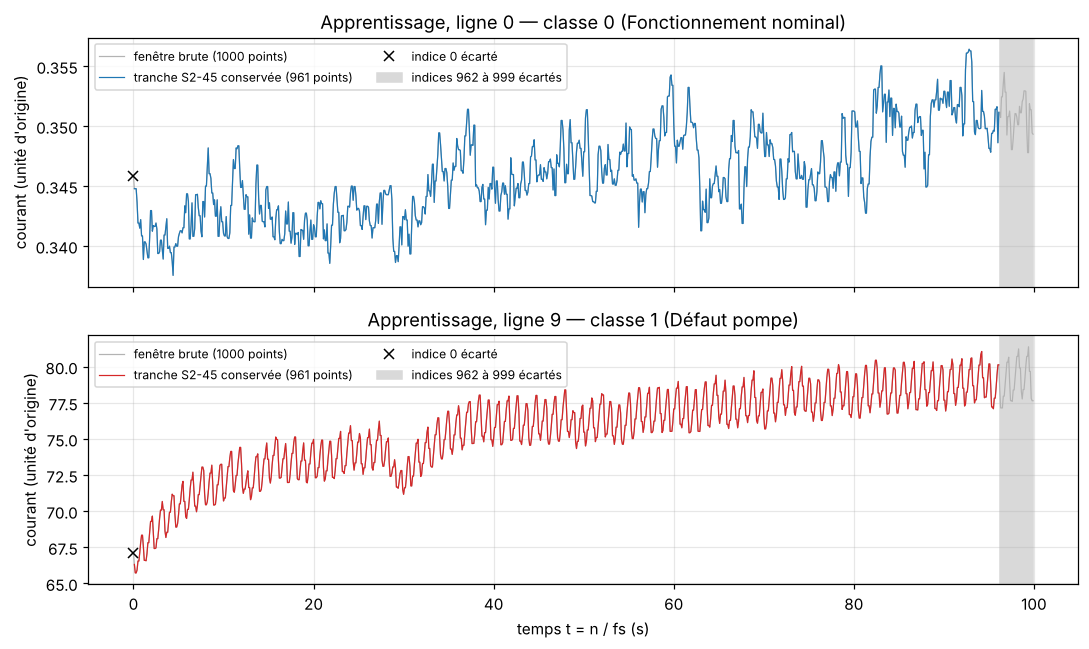

In [8]:
# =============================================================================
# A2.6  Deux fenêtres d'apprentissage (une par classe) et tranche retenue
# =============================================================================
i_nom = int(np.flatnonzero(Y_train == 0)[0])          # première fenêtre nominale
i_def = int(np.flatnonzero(Y_train == 1)[0])          # première fenêtre en défaut pompe

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
for ax, i in zip(axes, [i_nom, i_def]):
    ax.plot(t_brut, X_train_brut[i], color="0.7", lw=0.8, label="fenêtre brute (1000 points)")
    ax.plot(t_brut[DEBUT:FIN], X_train_cond[i], color=COULEURS[Y_train[i]], lw=0.8,
            label=f"tranche S2-45 conservée ({M} points)")
    ax.plot(t_brut[0], X_train_brut[i, 0], "kx", label="indice 0 écarté")
    ax.axvspan(t_brut[FIN], t_brut[-1], color="0.85", zorder=0, label="indices 962 à 999 écartés")
    ax.set_title(f"Apprentissage, ligne {i} — classe {Y_train[i]} ({CLASSES[Y_train[i]]})")
    ax.set_ylabel("courant (unité d'origine)")
    ax.legend(loc="upper left", fontsize=8, ncol=2)
axes[-1].set_xlabel("temps t = n / fs (s)")
plt.tight_layout()
plt.show()

**Lecture de A2.**

- **Décalage déclaré.** Avec $N = \lfloor\sqrt{1000}\rfloor = 31$, la source S2-45 conserve `x[1:N*N+1]`, soit les indices 1 à 961 ; la session 6 conservait les indices 0 à 960. Ce décalage d'un point est **conservé et annoncé**, pas corrigé en silence. La longueur carrée $N^2 = 961$ est historique : la DWT ne l'exige pas.
- **Instants et convention de durée.** L'échantillon d'indice $n$ est daté $t_n = n/f_s$ (le premier à 0 s, le dernier de la fenêtre brute à 99,9 s). La tranche va donc de 0,1 s à 96,1 s : l'écart entre premier et dernier instant vaut 96,0 s, tandis que la durée couverte, comptée comme $M/f_s$ (chaque point représente $\Delta t = 0{,}1$ s, comme « 1000 points = 100 s »), vaut 96,1 s.
- **Pourquoi aucun nouveau découpage apprentissage/test ?** Pour attribuer une différence d'erreurs au **seul changement de représentation**, tout le reste doit rester identique : mêmes lignes, mêmes étiquettes, même tranche. Un nouveau tirage changerait les exemples des deux côtés et mélangerait deux effets (données et représentation). Un tel tirage ne garantirait pas non plus l'indépendance, faute d'identifiants d'essai.

## 3. A3 — De chaque fenêtre à cinq caractéristiques

`pywt.wavedec` renvoie les coefficients dans l'ordre $[cA_5, cD_5, cD_4, cD_3, cD_2, cD_1]$. Chaque bloc $cD_j$ est reconstruit **seul** en un détail $D_j$ de 961 points avec `upcoef` (convention source : partie centrale de longueur `take = 961`), puis l'ordre est **inversé** pour obtenir la ligne $(r_1, r_2, r_3, r_4, r_5)$ associée à $D_1 \dots D_5$. *L'ordre D5 → D1 de la session 6 n'est pas repris sans le dire : la permutation est déclarée ici.*

$$E_j = \sum_{k=0}^{n-1} |D_j[k]|^2, \qquad r_j = \frac{E_j}{\sum_{\ell=1}^{5} E_\ell}.$$

Chaque $r_j \ge 0$ et $\sum_j r_j = 1$ lorsque le dénominateur est positif. Le dénominateur **exclut A5**. Ce sont des énergies relatives de détails (unité du signal au carré, sommées sur les points), **pas** des fractions d'énergie électrique en joules.

In [9]:
# =============================================================================
# A3.1  Détails reconstruits et fonction extraire_RWE
# =============================================================================
def details_reconstruits(signal, ondelette=ONDELETTE, niveau=NIVEAU):
    """Détails D1..D5 (lignes), chacun de la longueur du signal, convention source `upcoef`."""
    x = np.asarray(signal, dtype=float)
    coeffs = pywt.wavedec(x, ondelette, level=niveau)        # [cA5, cD5, cD4, cD3, cD2, cD1]
    details_5_vers_1 = []
    for position in range(1, niveau + 1):                   # position 1 -> cD5, ..., position 5 -> cD1
        j = niveau + 1 - position                            # niveau du détail
        details_5_vers_1.append(pywt.upcoef("d", coeffs[position], ondelette, level=j, take=x.size))
    return np.array(details_5_vers_1[::-1])                  # permutation déclarée : D1, D2, ..., D5

def extraire_RWE(signal, ondelette=ONDELETTE, niveau=NIVEAU):
    """Énergies relatives des détails : r_j = E_j / (E_1 + ... + E_5), j = 1..5 (A5 exclue)."""
    x = np.asarray(signal, dtype=float)
    if x.ndim != 1 or x.size == 0 or not np.isfinite(x).all():
        raise ValueError("signal 1D, fini et non vide attendu")
    D = details_reconstruits(x, ondelette, niveau)
    E = np.sum(np.abs(D) ** 2, axis=1)                       # E_j = somme des |D_j[k]|²
    E_total = E.sum()
    if not np.isfinite(E_total) or E_total <= 0:             # jamais de remplacement silencieux par 0
        raise ValueError("énergie des détails nulle : RWE indéfinie")
    return E / E_total

coeffs_ex = pywt.wavedec(X_train_cond[i_def], ONDELETTE, level=NIVEAU)
print("Longueurs [cA5, cD5, cD4, cD3, cD2, cD1] :", [len(c) for c in coeffs_ex])
print("Détails reconstruits (D1..D5, points)    :", details_reconstruits(X_train_cond[i_def]).shape)
print(f"RWE de la ligne {i_def} (D1..D5)           :", np.round(extraire_RWE(X_train_cond[i_def]), 4))

Longueurs [cA5, cD5, cD4, cD3, cD2, cD1] : [36, 36, 66, 126, 245, 484]
Détails reconstruits (D1..D5, points)    : (5, 961)
RWE de la ligne 9 (D1..D5)           : [0.0522 0.1957 0.6665 0.0457 0.0398]


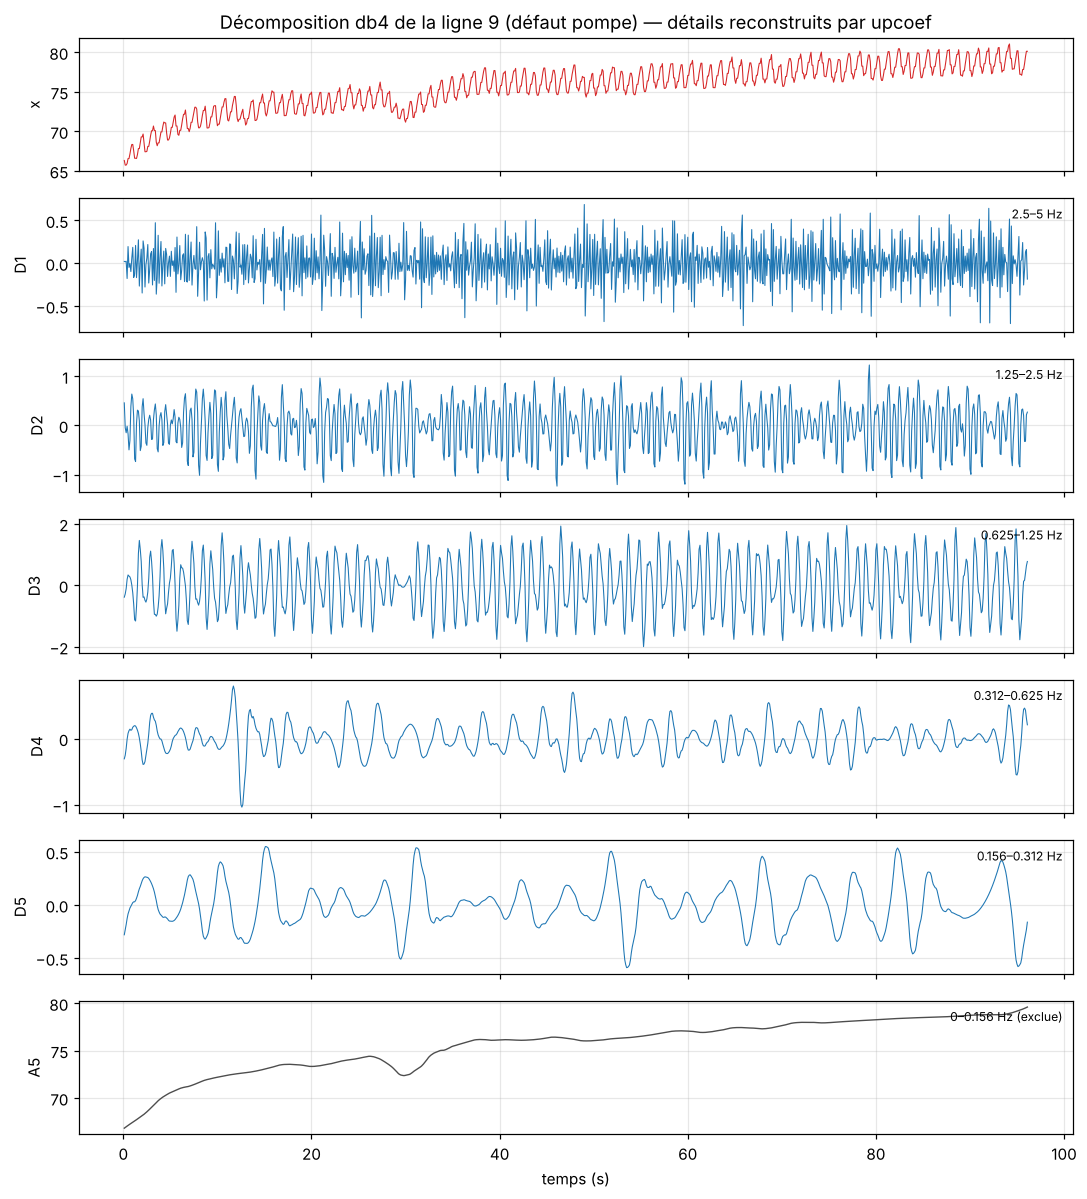

In [10]:
# =============================================================================
# A3.2  Visualiser la décomposition d'une fenêtre en défaut (A5 tracée mais exclue des RWE)
# =============================================================================
t_cond = t_brut[DEBUT:FIN]
D_ex = details_reconstruits(X_train_cond[i_def])
A5_ex = pywt.upcoef("a", coeffs_ex[0], ONDELETTE, level=NIVEAU, take=M)
bandes = [f"{FS / 2 ** (j + 1):.3g}–{FS / 2 ** j:.3g} Hz" for j in range(1, NIVEAU + 1)]

fig, axes = plt.subplots(NIVEAU + 2, 1, figsize=(10, 11), sharex=True)
axes[0].plot(t_cond, X_train_cond[i_def], color=COULEURS[1], lw=0.7)
axes[0].set_ylabel("x")
for j in range(NIVEAU):
    axes[j + 1].plot(t_cond, D_ex[j], lw=0.7)
    axes[j + 1].set_ylabel(f"D{j + 1}")
    axes[j + 1].text(0.99, 0.85, bandes[j], transform=axes[j + 1].transAxes, ha="right", fontsize=8)
axes[-1].plot(t_cond, A5_ex, color="0.3", lw=0.9)
axes[-1].set_ylabel("A5")
axes[-1].text(0.99, 0.85, f"0–{FS / 2 ** (NIVEAU + 1):.3g} Hz (exclue)", transform=axes[-1].transAxes,
              ha="right", fontsize=8)
axes[0].set_title(f"Décomposition db4 de la ligne {i_def} (défaut pompe) — détails reconstruits par upcoef")
axes[-1].set_xlabel("temps (s)")
plt.tight_layout()
plt.show()

In [11]:
# =============================================================================
# A3.3  Tableaux de caractéristiques : une ligne RWE par fenêtre + contrôles
# =============================================================================
NOMS_RWE = [f"r{j} (D{j})" for j in range(1, NIVEAU + 1)]
X_train = np.vstack([extraire_RWE(x) for x in X_train_cond])     # (384, 5)
X_test  = np.vstack([extraire_RWE(x) for x in X_test_cond])      # (96, 5)

sommes_train, sommes_test = X_train.sum(axis=1), X_test.sum(axis=1)
assert X_train.shape == (384, NIVEAU) and X_test.shape == (96, NIVEAU)
assert np.isfinite(X_train).all() and np.isfinite(X_test).all()
assert (X_train >= 0).all() and (X_test >= 0).all()
assert np.allclose(sommes_train, 1, atol=1e-12) and np.allclose(sommes_test, 1, atol=1e-12)

display(pd.DataFrame({
    "apprentissage": [X_train.shape, bool(np.isfinite(X_train).all()), X_train.min(), np.abs(sommes_train - 1).max()],
    "validation":    [X_test.shape,  bool(np.isfinite(X_test).all()),  X_test.min(),  np.abs(sommes_test - 1).max()],
}, index=["dimensions", "valeurs finies", "minimum (≥ 0 attendu)", "max |somme des r_j − 1|"]))

tableau_RWE = pd.DataFrame(100 * X_train, columns=NOMS_RWE)
tableau_RWE.insert(0, "classe", Y_train)
print("Cinq premières lignes d'apprentissage (RWE en %) :")
display(tableau_RWE.head().round(2))
print("Moyenne (écart-type) par classe, apprentissage, en % :")
moy, ect = tableau_RWE.groupby("classe")[NOMS_RWE].mean(), tableau_RWE.groupby("classe")[NOMS_RWE].std()
display(moy.round(2).astype(str) + " (" + ect.round(2).astype(str) + ")")

,apprentissage,validation
dimensions,"(384, 5)","(96, 5)"
valeurs finies,True,True
minimum (≥ 0 attendu),0.006,0.0072
max |somme des r_j − 1|,0.0,0.0


Cinq premières lignes d'apprentissage (RWE en %) :


,classe,r1 (D1),r2 (D2),r3 (D3),r4 (D4),r5 (D5)
0,0,7.65,10.84,22.65,34.09,24.78
1,0,7.96,11.75,22.44,34.97,22.87
2,0,7.40,9.77,25.53,35.34,21.96
3,0,7.89,12.90,21.34,22.94,34.94
4,0,3.13,4.88,20.27,39.25,32.47


Moyenne (écart-type) par classe, apprentissage, en % :


,r1 (D1),r2 (D2),r3 (D3),r4 (D4),r5 (D5)
classe,,,,,
0,4.67 (3.07),7.75 (5.29),22.65 (16.55),25.23 (8.75),39.7 (20.08)
1,4.98 (0.28),17.95 (1.55),64.16 (3.43),4.31 (0.65),8.6 (3.52)


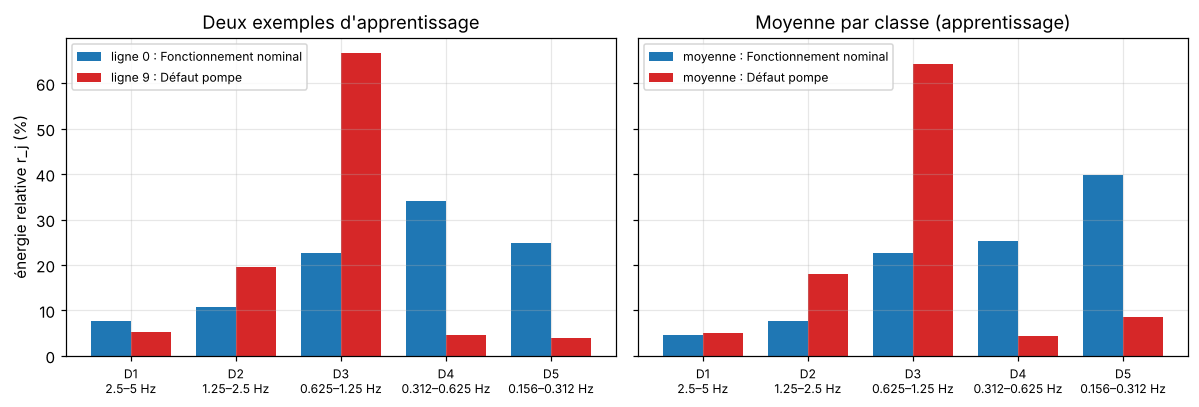

In [12]:
# =============================================================================
# A3.4  Les cinq pourcentages : deux exemples d'apprentissage et moyennes par classe
# =============================================================================
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
pos, largeur = np.arange(1, NIVEAU + 1), 0.38
for decalage, i in zip([-largeur / 2, largeur / 2], [i_nom, i_def]):
    axes[0].bar(pos + decalage, 100 * X_train[i], width=largeur, color=COULEURS[Y_train[i]],
                label=f"ligne {i} : {CLASSES[Y_train[i]]}")
for decalage, c in zip([-largeur / 2, largeur / 2], [0, 1]):
    axes[1].bar(pos + decalage, 100 * X_train[Y_train == c].mean(axis=0), width=largeur,
                color=COULEURS[c], label=f"moyenne : {CLASSES[c]}")
axes[0].set_title("Deux exemples d'apprentissage")
axes[1].set_title("Moyenne par classe (apprentissage)")
for ax in axes:
    ax.set_xticks(pos, [f"D{j}\n{b}" for j, b in zip(pos, bandes)], fontsize=8)
    ax.legend(fontsize=8)
axes[0].set_ylabel("énergie relative r_j (%)")
plt.tight_layout()
plt.show()

**Bandes nominales et information retirée par la normalisation.**

Avec $f_s = 10$ Hz (Nyquist 5 Hz), le détail $D_j$ couvre nominalement $[f_s/2^{j+1},\, f_s/2^{j}]$ :

| Composante | Bande nominale | Périodes | Lecture possible |
|---|---|---|---|
| D1 | 2,5 – 5 Hz | 0,2 – 0,4 s | fluctuations rapides, bruit de mesure |
| D2 | 1,25 – 2,5 Hz | 0,4 – 0,8 s | oscillations rapides |
| D3 | 0,625 – 1,25 Hz | 0,8 – 1,6 s | oscillations de l'ordre de la seconde |
| D4 | 0,3125 – 0,625 Hz | 1,6 – 3,2 s | oscillations lentes (pulsations éventuelles) |
| D5 | 0,156 – 0,3125 Hz | 3,2 – 6,4 s | variations lentes |
| A5 (exclue) | 0 – 0,156 Hz | > 6,4 s | niveau moyen, dérives, point de fonctionnement |

Ces bandes sont **nominales** : les filtres db4 ne sont pas idéaux et les bandes voisines se recouvrent. Une forte énergie dans une bande ne désigne pas à elle seule un mécanisme (pompe, régulation ou capteur).

La normalisation $r_j = E_j/\sum E_\ell$ **retire** :
- l'**amplitude absolue** des fluctuations : une fenêtre dix fois plus agitée mais de même répartition spectrale a les mêmes RWE (invariance au gain, perte de l'unité et de l'étalonnage) ;
- tout le contenu de **A5** : niveau moyen du courant, dérives lentes, point de fonctionnement ;
- un **degré de liberté** : 5 nombres de somme 1, donc 4 coordonnées indépendantes seulement ;
- la **chronologie** dans la fenêtre (quand l'énergie apparaît), le signe et la phase.

Elle garde la **répartition relative de l'énergie entre échelles**. Un défaut qui changerait surtout l'amplitude ou le niveau moyen, sans déplacer l'énergie entre bandes, deviendrait invisible pour cette représentation.

## 4. A4 — Classer et évaluer la première branche

Le KNN mémorise les exemples étiquetés et prédit la classe majoritaire parmi les $k = 4$ plus proches voisins, au sens de $d(x,z)=\sqrt{\sum_{j=1}^{5}(x_j-z_j)^2}$. Avec $k$ pair, un vote **2 contre 2** est possible : la règle de départage de l'implémentation fait partie des conditions de reproductibilité (elle est mesurée en A4.3).

Le défaut étant la classe positive (lignes = classes réelles, colonnes = classes prédites, ordre [0, 1]) :

$$C=\begin{pmatrix} VN & FP\\ FN & VP\end{pmatrix},\quad \mathrm{Acc}=\frac{VN+VP}{n},\quad R_D=\frac{VP}{VP+FN},\quad F_A=\frac{FP}{VN+FP},\quad \mathrm{BA}=\frac12\Big(\frac{VN}{VN+FP}+R_D\Big).$$

Les taux sont calculés **à partir des matrices**, jamais à partir d'effectifs recopiés.

In [13]:
# =============================================================================
# A4.1  Outils communs : même KNN pour tous, matrices et taux calculés depuis la matrice
# =============================================================================
def nouveau_knn():
    """Réglage unique de la comparaison (session 4) : k = 4, euclidienne, votes uniformes."""
    return KNeighborsClassifier(n_neighbors=K_VOISINS, weights="uniform", metric="minkowski", p=2)

def matrices_confusion(y_vrai, y_pred):
    """Matrice brute (effectifs) et matrice normalisée par ligne (divisée par l'effectif réel)."""
    C = confusion_matrix(y_vrai, y_pred, labels=[0, 1])
    C_norm = confusion_matrix(y_vrai, y_pred, labels=[0, 1], normalize="true")
    return C, C_norm

def taux_depuis_matrice(C):
    """Exactitude, exactitude équilibrée, rappel défaut, taux de fausses alarmes, VN/FP/FN/VP."""
    (VN, FP), (FN, VP) = C
    R_D = VP / (VP + FN) if VP + FN else np.nan
    F_A = FP / (VN + FP) if VN + FP else np.nan
    return {"Acc": (VN + VP) / C.sum(), "BA": 0.5 * ((1 - F_A) + R_D), "R_D": R_D, "F_A": F_A,
            "VN": int(VN), "FP": int(FP), "FN": int(FN), "VP": int(VP)}

def tableau_taux(matrices):
    """{nom: matrice} -> tableau lisible (taux en %, effectifs entiers)."""
    lignes = {}
    for nom, C in matrices.items():
        t = taux_depuis_matrice(C)
        lignes[nom] = {"exactitude (%)": 100 * t["Acc"], "exactitude équilibrée (%)": 100 * t["BA"],
                       "rappel défaut R_D (%)": 100 * t["R_D"], "fausses alarmes F_A (%)": 100 * t["F_A"],
                       "VN": t["VN"], "FP": t["FP"], "FN": t["FN"], "VP": t["VP"]}
    return pd.DataFrame.from_dict(lignes, orient="index").round(2)

def tracer_matrices(y_vrai, y_pred, titre):
    """Matrice brute et matrice normalisée par ligne, côte à côte (API ConfusionMatrixDisplay)."""
    fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
    for ax, norm, sous_titre, fmt in zip(axes, [None, "true"], ["effectifs", "normalisée par ligne"], ["d", ".2f"]):
        ConfusionMatrixDisplay.from_predictions(y_vrai, y_pred, labels=[0, 1], normalize=norm,
                                                display_labels=["0 nominal", "1 défaut pompe"],
                                                values_format=fmt, cmap="Blues", colorbar=False, ax=ax)
        ax.set_title(f"{titre}\n({sous_titre})", fontsize=10)
        ax.set_xlabel("classe prédite")
        ax.set_ylabel("classe réelle")
        ax.grid(False)
    plt.tight_layout()
    plt.show()

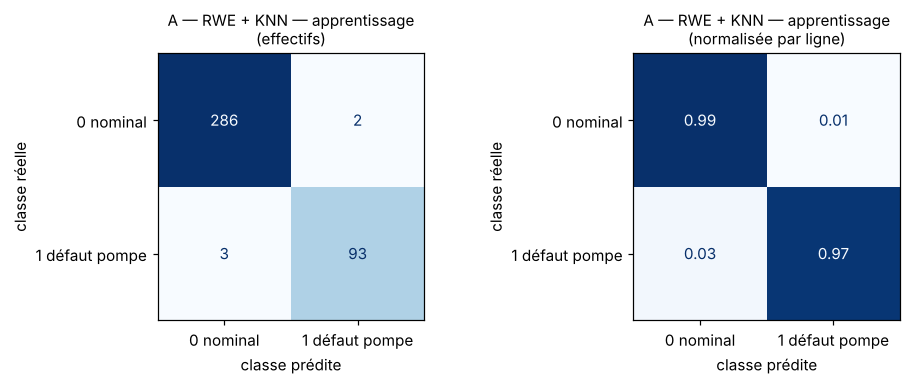

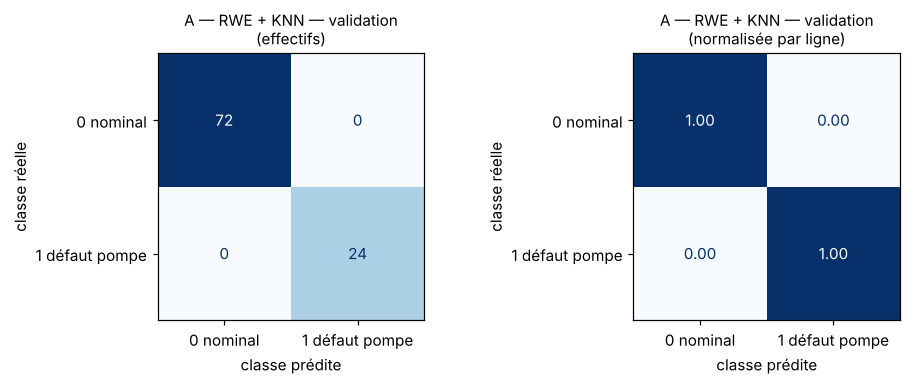

,exactitude (%),exactitude équilibrée (%),rappel défaut R_D (%),fausses alarmes F_A (%),VN,FP,FN,VP
A apprentissage,98.7,98.09,96.88,0.69,286,2,3,93
A validation,100.0,100.00,100.00,0.00,72,0,0,24


In [14]:
# =============================================================================
# A4.2  Branche A : apprendre model_KNN sur X_train / Y_train, prédire séparément
# =============================================================================
model_KNN = nouveau_knn().fit(X_train, Y_train)
pred_train_A = model_KNN.predict(X_train)       # apprentissage
pred_test_A  = model_KNN.predict(X_test)        # validation

C_train_A, C_train_A_norm = matrices_confusion(Y_train, pred_train_A)
C_test_A,  C_test_A_norm  = matrices_confusion(Y_test,  pred_test_A)
tracer_matrices(Y_train, pred_train_A, "A — RWE + KNN — apprentissage")
tracer_matrices(Y_test,  pred_test_A,  "A — RWE + KNN — validation")
tableau_taux({"A apprentissage": C_train_A, "A validation": C_test_A})

In [15]:
# =============================================================================
# A4.3  Égalités de vote 2 contre 2 (k pair) : mesure de la règle de départage
# =============================================================================
def egalites_de_vote(modele, X):
    """Indices où 2 voisins sur 4 sont « défaut » : la prédiction dépend de la règle de départage."""
    part_defaut = modele.predict_proba(X)[:, 1]
    return np.flatnonzero(np.isclose(part_defaut, 0.5))

classes_sur_egalite = []
for nom_jeu, X_, pred_ in [("apprentissage", X_train, pred_train_A), ("validation", X_test, pred_test_A)]:
    idx = egalites_de_vote(model_KNN, X_)
    classes_sur_egalite += pred_[idx].tolist()
    print(f"{nom_jeu:14s}: {idx.size:3d} égalité(s) 2–2 ; classes attribuées : "
          f"{np.unique(pred_[idx]).tolist() if idx.size else '-'}")
if classes_sur_egalite and set(classes_sur_egalite) == {0}:
    print("Règle observée : en cas d'égalité 2–2, scikit-learn attribue la classe de plus petit indice (0 = nominal).")
elif not classes_sur_egalite:
    print("Aucune égalité 2–2 : la règle de départage n'intervient pas ici.")

tA = taux_depuis_matrice(C_test_A)
md(f"**Résultat A (validation)** : exactitude {fr(100 * tA['Acc'])} %, exactitude équilibrée "
   f"{fr(100 * tA['BA'])} %, rappel défaut {fr(100 * tA['R_D'])} %, fausses alarmes {fr(100 * tA['F_A'])} % "
   f"— soit **{tA['FP']} fausse(s) alarme(s)** et **{tA['FN']} défaut(s) manqué(s)** sur {len(Y_test)} fenêtres.")

apprentissage :   5 égalité(s) 2–2 ; classes attribuées : [0]
validation    :   1 égalité(s) 2–2 ; classes attribuées : [0]
Règle observée : en cas d'égalité 2–2, scikit-learn attribue la classe de plus petit indice (0 = nominal).


**Résultat A (validation)** : exactitude 100,00 %, exactitude équilibrée 100,00 %, rappel défaut 100,00 %, fausses alarmes 0,00 % — soit **0 fausse(s) alarme(s)** et **0 défaut(s) manqué(s)** sur 96 fenêtres.

**Interprétation des erreurs de la branche A.**

- **Lecture des matrices.** La ligne « 1 défaut pompe » de la matrice normalisée donne directement le rappel défaut ($R_D$) et la proportion de défauts manqués ; la ligne « 0 nominal » donne le taux de fausses alarmes ($F_A$).
- **Apprentissage optimiste.** Sur l'apprentissage, chaque fenêtre est son propre plus proche voisin (distance nulle) : elle se donne un vote sur quatre. Le score d'apprentissage n'est donc pas une estimation de généralisation.
- **Pourquoi l'exactitude ne suffit pas.** Les deux jeux sont nominaux à 75 % : prédire toujours « nominal » donne 75 % d'exactitude avec un rappel défaut nul. L'exactitude équilibrée et le couple (FP, FN) sont plus parlants.
- **Égalités 2–2.** scikit-learn attribue alors la classe 0 : chaque égalité est un défaut manqué potentiel. Une autre implémentation (ou $k$ impair) pourrait décider autrement : c'est une condition de reproductibilité.

## 5. A5 — Bilan de 15 minutes

**5 min — chaîne signal → étiquette.** Fenêtre de courant (1000 points à 10 Hz) → tranche `x[1:962]` (961 points) → `wavedec` db4 à 5 niveaux → 5 détails reconstruits par `upcoef` → 5 énergies $E_j$ → 5 RWE de somme 1 → KNN ($k = 4$) → classe 0/1 → comparaison à l'étiquette expérimentale. L'étiquette décrit l'essai ; elle ne prouve pas le mécanisme.

**5 min — dénominateur, ordre, FP/FN.** Le dénominateur des RWE est $E_1+\dots+E_5$ (**A5 exclue**). L'ordre des critères est $(r_1,\dots,r_5) \leftrightarrow (D_1,\dots,D_5)$, de la bande la plus rapide (2,5–5 Hz) à la plus lente (0,16–0,31 Hz), soit l'inverse de l'ordre de `wavedec`. **FP** = fenêtre nominale prédite en défaut (fausse alarme) ; **FN** = fenêtre en défaut prédite nominale (défaut manqué).

**5 min — auto-évaluation (0 non acquis, 1 avec aide, 2 autonome).**

| Compétence | Note | Trace dans le notebook |
|---|---|---|
| Préparer X (tranche, RWE, contrôles) | 2 | A2.5, A3.1, A3.3 (assertions) |
| Apprendre le KNN | 2 | A4.1, A4.2 |
| Interpréter les erreurs (FP, FN, BA, égalités) | 2 | A4.2, A4.3 |

**Question restante avant le bloc ACP.** Les RWE n'ont que 4 degrés de liberté et l'ACP ignore les étiquettes : les directions de **faible variance** qu'elle supprimera portent-elles une partie de l'information qui sépare les classes ?

## 6. B1 — ACP d'un espace de caractéristiques contraint

Soit $X \in \mathbb{R}^{384\times 5}$ (RWE d'apprentissage) et $\mu$ ses moyennes de colonnes :

$$X_c = X - \mathbf{1}\mu^T,\qquad C = \frac{X_c^T X_c}{383},\qquad C v_j = \lambda_j v_j,\qquad Z_q = X_c V_q .$$

L'ACP maximise la variance projetée selon des directions orthogonales. Le calcul **centre seulement** : ni standardisation, ni blanchiment. Les étiquettes n'interviennent pas.

**Cinq coordonnées, au plus quatre directions centrées.** Chaque ligne vérifie $x_i^T\mathbf{1}_5 = 1$, donc $\mu^T\mathbf{1}_5 = \frac1n\sum_i x_i^T\mathbf{1}_5 = 1$ et $X_c\mathbf{1}_5 = 0$. Toutes les lignes centrées sont dans l'hyperplan orthogonal à $\mathbf{1}_5$ (dimension 4) : $\mathrm{rang}(X_c) \le 4$ et $C\mathbf{1}_5 = 0$. Ainsi $\mathbf{1}_5/\sqrt5$ est vecteur propre de valeur propre **nulle**, à la précision numérique près. C'est une **contrainte de normalisation** (géométrie du simplexe), pas la preuve d'une panne de capteur.

In [16]:
# =============================================================================
# B1.1  Géométrie calculée à la main : moyenne, centrage, covariance, valeurs propres
# =============================================================================
n_app = X_train.shape[0]
mu = X_train.mean(axis=0)                           # (5,)
X_c = X_train - mu                                  # (384, 5) = X - 1 mu^T
C_cov = X_c.T @ X_c / (n_app - 1)                   # (5, 5), dénominateur 383
un5 = np.ones(NIVEAU)

valeurs_propres, vecteurs_propres = np.linalg.eigh(C_cov)    # matrice symétrique : ordre croissant
ordre = np.argsort(valeurs_propres)[::-1]                    # on trie par ordre décroissant
valeurs_propres, vecteurs_propres = valeurs_propres[ordre], vecteurs_propres[:, ordre]

pd.Series({
    "μᵀ 1₅ (attendu : 1)": f"{mu @ un5:.15f}",
    "max |X_c 1₅| (attendu : ≈ 0)": f"{np.abs(X_c @ un5).max():.2e}",
    "max |C 1₅| (attendu : ≈ 0)": f"{np.abs(C_cov @ un5).max():.2e}",
    "rang numérique de X_c": np.linalg.matrix_rank(X_c),
    "λ1 (plus grande)": f"{valeurs_propres[0]:.4e}",
    "λ5 (plus petite)": f"{valeurs_propres[-1]:.2e}",
    "|λ5| / λ1": f"{abs(valeurs_propres[-1]) / valeurs_propres[0]:.2e}",
    "vecteur propre de λ5 (attendu : ±1/√5 = ±0.4472)": np.round(vecteurs_propres[:, -1], 4),
}, name="valeur").to_frame()

,valeur
μᵀ 1₅ (attendu : 1),1.000000000000000
max |X_c 1₅| (attendu : ≈ 0),2.29e-16
max |C 1₅| (attendu : ≈ 0),2.43e-17
rang numérique de X_c,4
λ1 (plus grande),1.0632e-01
λ5 (plus petite),-3.86e-18
|λ5| / λ1,3.63e-17
vecteur propre de λ5 (attendu : ±1/√5 = ±0.4472),"[0.4472, 0.4472, 0.4472, 0.4472, 0.4472]"


In [17]:
# =============================================================================
# B1.2  ACP apprise sur l'APPRENTISSAGE seul ; validation transformée par le MÊME objet
# =============================================================================
model_ACP = PCA()                         # 5 composantes, centrage seul, whiten=False par défaut
model_ACP.fit(X_train)                    # aucune étiquette : apprentissage non supervisé
X_train_ACP = model_ACP.transform(X_train)        # (384, 5)
X_test_ACP  = model_ACP.transform(X_test)         # (96, 5) avec la moyenne et les directions d'apprentissage

display(pd.DataFrame({"dimensions": {
    "moyenne μ (model_ACP.mean_)": model_ACP.mean_.shape,
    "covariance C (model_ACP.get_covariance())": model_ACP.get_covariance().shape,
    "directions V (model_ACP.components_.T)": model_ACP.components_.T.shape,
    "directions retenues V_q (q = 3)": model_ACP.components_[:NBR_COMPOSANTE_CONSERVE].T.shape,
    "scores d'apprentissage Z_train": X_train_ACP.shape,
    "scores de validation Z_test": X_test_ACP.shape,
}}))

# Cohérence avec le calcul à la main (les directions sont définies au signe près)
Z_main = X_c @ vecteurs_propres
signes = np.sign(np.sum(Z_main * X_train_ACP, axis=0)); signes[signes == 0] = 1
print("max |μ_sklearn − μ|              :", np.abs(model_ACP.mean_ - mu).max())
print("max |C_sklearn − C|              :", np.abs(model_ACP.get_covariance() - C_cov).max())
print("max |λ_sklearn − λ_eigh|         :", np.abs(model_ACP.explained_variance_ - valeurs_propres).max())
print("max |Z_sklearn − X_c V| (signe)  :", np.abs(X_train_ACP - Z_main * signes).max())
print("moyennes des scores d'apprentissage :", np.round(X_train_ACP.mean(axis=0), 12))
print("blanchiment (whiten) :", model_ACP.whiten)

,dimensions
moyenne μ (model_ACP.mean_),"(5,)"
covariance C (model_ACP.get_covariance()),"(5, 5)"
directions V (model_ACP.components_.T),"(5, 5)"
directions retenues V_q (q = 3),"(5, 3)"
scores d'apprentissage Z_train,"(384, 5)"
scores de validation Z_test,"(96, 5)"


max |μ_sklearn − μ|              : 0.0
max |C_sklearn − C|              : 1.3877787807814457e-16
max |λ_sklearn − λ_eigh|         : 1.1288232441424908e-16
max |Z_sklearn − X_c V| (signe)  : 1.7893306877866186e-14
moyennes des scores d'apprentissage : [-0.  0. -0. -0.  0.]
blanchiment (whiten) : False


,λ_j,η_j (%),H_q (%)
CP1,1.0632e-01,88.078868,88.078868
CP2,1.3319e-02,11.034402,99.113269
CP3,1.0116e-03,0.838087,99.951356
CP4,5.8715e-05,0.048644,100.000000
CP5,1.0902e-16,0.000000,100.000000


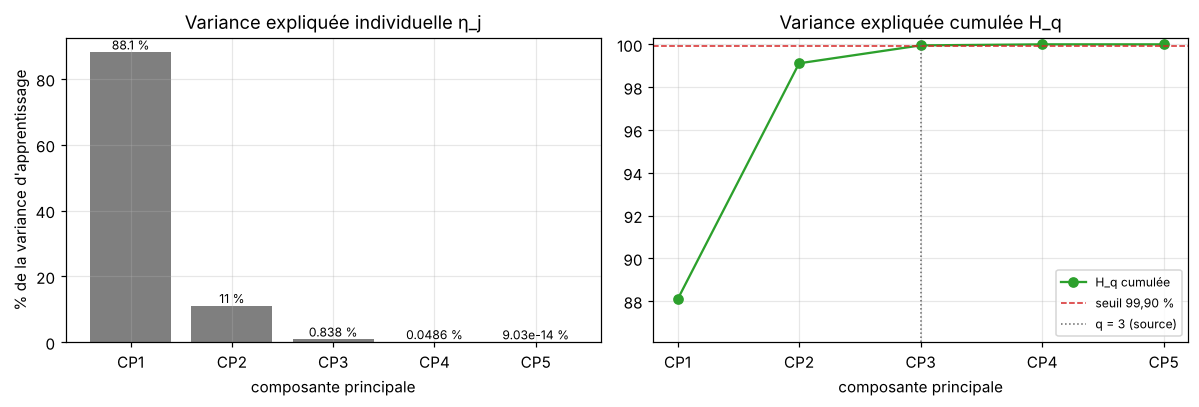

In [18]:
# =============================================================================
# B1.3  Variances expliquées individuelles et cumulées (valeurs d'apprentissage non arrondies)
# =============================================================================
eta = model_ACP.explained_variance_ratio_           # η_j = λ_j / Σ λ
H = np.cumsum(eta)                                  # H_q = Σ_{j≤q} η_j

display(pd.DataFrame({"λ_j": [f"{v:.4e}" for v in model_ACP.explained_variance_],
                      "η_j (%)": [f"{100 * e:.6f}" for e in eta],
                      "H_q (%)": [f"{100 * h:.6f}" for h in H]},
                     index=[f"CP{j}" for j in range(1, NIVEAU + 1)]))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
pos = np.arange(1, NIVEAU + 1)
barres = axes[0].bar(pos, 100 * eta, color="tab:gray")
axes[0].bar_label(barres, labels=[f"{100 * e:.3g} %" for e in eta], fontsize=8)
axes[0].set_title("Variance expliquée individuelle η_j")
axes[0].set_ylabel("% de la variance d'apprentissage")
axes[1].plot(pos, 100 * H, "o-", color="tab:green", label="H_q cumulée")
axes[1].axhline(100 * SEUIL_VARIANCE, color="tab:red", ls="--", lw=1, label="seuil 99,90 %")
axes[1].axvline(NBR_COMPOSANTE_CONSERVE, color="0.4", ls=":", lw=1, label="q = 3 (source)")
axes[1].set_ylim(max(0.0, 100 * H[0] - 2), 100.3)
axes[1].set_title("Variance expliquée cumulée H_q")
axes[1].legend(fontsize=8)
for ax in axes:
    ax.set_xticks(pos, [f"CP{j}" for j in pos])
    ax.set_xlabel("composante principale")
plt.tight_layout()
plt.show()

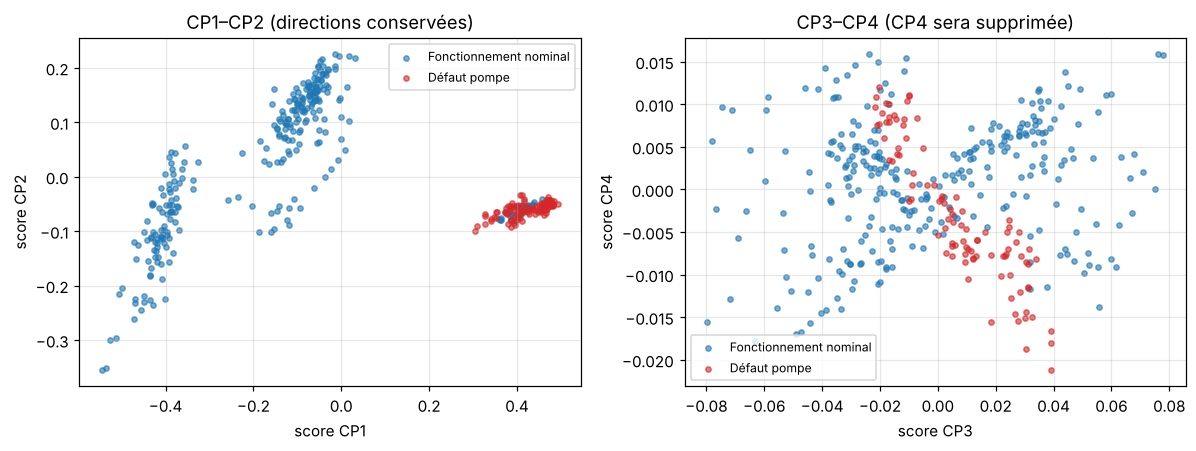

In [19]:
# =============================================================================
# B1.4  Nuage d'apprentissage dans les plans CP1–CP2 et CP3–CP4 (couleurs = classes connues)
# =============================================================================
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, (a, b) in zip(axes, [(0, 1), (2, 3)]):
    for c in [0, 1]:
        ax.scatter(X_train_ACP[Y_train == c, a], X_train_ACP[Y_train == c, b], s=12, alpha=0.6,
                   color=COULEURS[c], label=CLASSES[c])
    ax.set_xlabel(f"score CP{a + 1}")
    ax.set_ylabel(f"score CP{b + 1}")
    ax.legend(fontsize=8)
axes[0].set_title("CP1–CP2 (directions conservées)")
axes[1].set_title("CP3–CP4 (CP4 sera supprimée)")
plt.tight_layout()
plt.show()

**Lecture de B1.** La plus petite valeur propre est nulle à la précision machine et son vecteur propre est $\pm\mathbf{1}_5/\sqrt5$ : c'est la signature de la contrainte $\sum_j r_j = 1$. Les couleurs de classe aident à lire les nuages mais n'ont **pas** servi à apprendre l'ACP.

L'ACP complète est une **rotation** des coordonnées centrées (base orthonormée) : elle conserve toutes les distances. Réduire $q$ est une **projection** : elle peut rejeter des directions utiles aux classes même si elles portent peu de variance totale. Ici, garder $q = 4$ ne perdrait rien (CP5 est identiquement nulle), alors que $q = 3$ supprime la CP4.

## 7. B2 — Choisir une dimension et reproduire S2-45B

On note $\eta_j = \lambda_j/\sum_\ell \lambda_\ell$ et $H_q = \sum_{j=1}^{q}\eta_j$. La consigne source demande plus de 99,90 % de variance : $q_{seuil}$ est le plus petit $q$ tel que $H_q > 0{,}9990$, calculé sur les valeurs **non arrondies** de l'**apprentissage**. Le code source fixe séparément `nbr_composante_conserve = 3`.

Deux règles de conduite : la variance expliquée **n'est pas** une exactitude diagnostique ; un paramètre source **n'est pas** remplacé discrètement après avoir regardé les résultats de validation. On garde donc $q = 3$ pour la branche B et on rapporte $q_{seuil}$ comme information.

In [20]:
# =============================================================================
# B2  q_seuil (consigne) comparé à nbr_composante_conserve = 3 (code source)
# =============================================================================
au_dessus = np.flatnonzero(H > SEUIL_VARIANCE)
q_seuil = int(au_dessus[0] + 1) if au_dessus.size else NIVEAU
nbr_composante_conserve = NBR_COMPOSANTE_CONSERVE

for q in range(1, NIVEAU + 1):
    print(f"q = {q} : H_q = {100 * H[q - 1]:.6f} %   {'> 99,90 %' if H[q - 1] > SEUIL_VARIANCE else '≤ 99,90 %'}")
print(f"\nq_seuil = {q_seuil}   |   nbr_composante_conserve (source) = {nbr_composante_conserve}")
print(f"Pourcentage cumulé réel à trois composantes : H_3 = {100 * H[2]:.6f} %")

if q_seuil == nbr_composante_conserve:
    verdict = "la règle des 99,90 % et le code source **coïncident** (q = 3)."
elif q_seuil < nbr_composante_conserve:
    verdict = (f"la règle des 99,90 % suffirait avec **q = {q_seuil}** ; le code source garde une marge "
               f"et conserve 3 composantes.")
else:
    verdict = (f"la règle des 99,90 % demanderait **q = {q_seuil}** ; avec q = 3, le code source reste "
               f"sous le seuil (H₃ = {fr(100 * H[2], 4)} %).")
md(f"**Constat B2** : {verdict} La branche B reproduit le code source avec **q = {nbr_composante_conserve}**, "
   f"choix figé avant toute consultation de ses résultats de validation. H₃ = {fr(100 * H[2], 4)} % mesure une "
   f"variance conservée, pas un pourcentage de défauts reconnus.")

q = 1 : H_q = 88.078868 %   ≤ 99,90 %
q = 2 : H_q = 99.113269 %   ≤ 99,90 %
q = 3 : H_q = 99.951356 %   > 99,90 %
q = 4 : H_q = 100.000000 %   > 99,90 %
q = 5 : H_q = 100.000000 %   > 99,90 %

q_seuil = 3   |   nbr_composante_conserve (source) = 3
Pourcentage cumulé réel à trois composantes : H_3 = 99.951356 %


**Constat B2** : la règle des 99,90 % et le code source **coïncident** (q = 3). La branche B reproduit le code source avec **q = 3**, choix figé avant toute consultation de ses résultats de validation. H₃ = 99,9514 % mesure une variance conservée, pas un pourcentage de défauts reconnus.

## 8. B3 — Apprendre le classifieur réduit

`X_train_reduit` et `X_test_reduit` sont formés des **trois premiers scores**. Un **nouveau** KNN à quatre voisins (mêmes réglages) est appris. Les lignes de validation restent alignées avec leurs étiquettes : aucune ligne n'est réordonnée, et la projection traite chaque ligne indépendamment (vérifié ci-dessous).

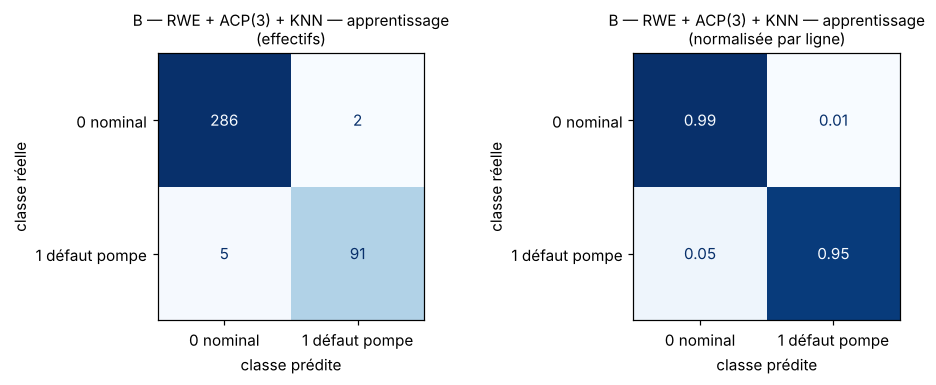

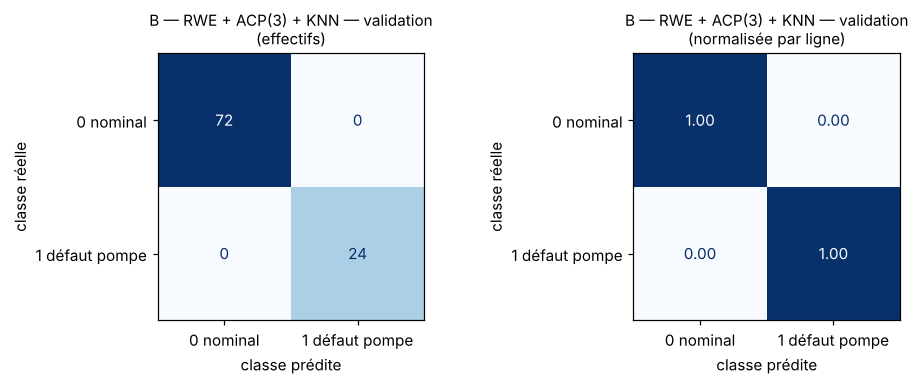

égalités 2–2, apprentissage: 8
égalités 2–2, validation   : 1


,exactitude (%),exactitude équilibrée (%),rappel défaut R_D (%),fausses alarmes F_A (%),VN,FP,FN,VP
A validation,100.00,100.00,100.00,0.00,72,0,0,24
B apprentissage,98.18,97.05,94.79,0.69,286,2,5,91
B validation,100.00,100.00,100.00,0.00,72,0,0,24


In [21]:
# =============================================================================
# B3.1  Branche B : 3 premiers scores puis KNN (k = 4)
# =============================================================================
X_train_reduit = X_train_ACP[:, :nbr_composante_conserve]      # (384, 3)
X_test_reduit  = X_test_ACP[:,  :nbr_composante_conserve]      # (96, 3)
assert X_train_reduit.shape == (384, 3) and X_test_reduit.shape == (96, 3)

# Alignement : projeter la validation à l'envers puis la remettre à l'endroit redonne les mêmes scores
assert np.allclose(model_ACP.transform(X_test[::-1])[::-1], X_test_ACP)
assert len(X_test_reduit) == len(Y_test) == len(X_test_cond)

model_KNN_reduit = nouveau_knn().fit(X_train_reduit, Y_train)
pred_train_B = model_KNN_reduit.predict(X_train_reduit)
pred_test_B  = model_KNN_reduit.predict(X_test_reduit)

C_train_B, C_train_B_norm = matrices_confusion(Y_train, pred_train_B)
C_test_B,  C_test_B_norm  = matrices_confusion(Y_test,  pred_test_B)
tracer_matrices(Y_train, pred_train_B, "B — RWE + ACP(3) + KNN — apprentissage")
tracer_matrices(Y_test,  pred_test_B,  "B — RWE + ACP(3) + KNN — validation")

for nom_jeu, X_ in [("apprentissage", X_train_reduit), ("validation", X_test_reduit)]:
    print(f"égalités 2–2, {nom_jeu:13s}: {egalites_de_vote(model_KNN_reduit, X_).size}")
tableau_taux({"A validation": C_test_A, "B apprentissage": C_train_B, "B validation": C_test_B})

### Repère 3 h + 1 h

Les trois premières heures s'arrêtent ici. La cellule suivante enregistre les matrices, l'objet ACP, la dimension retenue et des notes explicatives. Pour reprendre la dernière heure sans tout recalculer : `reprise = joblib.load(chemin_reprise)`. (Dans Colab, un fichier enregistré hors de Drive disparaît à la fin de la session : le télécharger si besoin.)

In [22]:
# =============================================================================
# B3.2  Sauvegarde du point de reprise
# =============================================================================
point_de_reprise = {
    "conventions": {"tranche": (DEBUT, FIN), "ondelette": ONDELETTE, "niveau": NIVEAU,
                    "k": K_VOISINS, "q": nbr_composante_conserve, "q_seuil": q_seuil},
    "donnees": {"X_train": X_train, "X_test": X_test, "Y_train": Y_train, "Y_test": Y_test},
    "model_ACP": model_ACP,
    "matrices": {"C_train_A": C_train_A, "C_test_A": C_test_A, "C_train_B": C_train_B, "C_test_B": C_test_B},
    "predictions": {"pred_test_A": pred_test_A, "pred_test_B": pred_test_B},
    "notes": ("RWE db4 à 5 niveaux (upcoef, ordre D1..D5, A5 exclue) sur x[1:962] ; ACP centrée non "
              "blanchie apprise sur l'apprentissage ; q = 3 fixé par la source ; KNN k = 4, votes uniformes."),
}
for dossier in [DOSSIER_UTILISE, Path.cwd()]:
    try:
        chemin_reprise = Path(dossier) / "Session7_reprise_B3.joblib"
        joblib.dump(point_de_reprise, chemin_reprise)
        print("Point de reprise enregistré :", chemin_reprise)
        break
    except OSError as erreur:
        print("Écriture impossible dans", dossier, "->", erreur)

Point de reprise enregistré : /content/Session7_reprise_B3.joblib


## 9. B4 — Comparer les prédictions, pas seulement les scores

Une référence à **fenêtre identique** recalcule les six critères SD, RMS, CF, SK, KU, SF sur la même tranche S2-45 et apprend un KNN à $k = 4$, avec les réglages de la session 4 (critères bruts, sans mise à l'échelle). CF conserve la formule source du **facteur de dégagement** ($\max|S| / (\frac1M\sum\sqrt{|S|})^2$) et KU n'est pas un excès. Cette référence peut différer légèrement de la session 4, qui débutait à l'indice 0.

Sans mise à l'échelle, les critères qui ont l'unité du signal (SD, RMS) et ceux sans dimension (CF, SK, KU, SF) n'ont pas le même poids dans la distance euclidienne : la part de variance de chaque critère est affichée pour le mesurer. Modifier cette référence (standardisation) serait un nouveau protocole déclaré, pas un réglage à faire après coup.

,SD,RMS,CF,SK,KU,SF
mean,0.6380,33.1641,1.0289e+00,-0.0960,2.3508,1.0001e+00
std,0.6704,27.4656,1.7353e-02,0.2574,0.3919,1.2614e-04
min,0.0027,0.3291,1.0009e+00,-0.7272,1.7065,1.0000e+00
max,2.9469,79.6092,1.0729e+00,0.7023,3.4592,1.0008e+00
part de la variance totale (%),0.0595,99.9113,3.9884e-05,0.0088,0.0203,2.1072e-09


Sans mise à l'échelle, **RMS** porte 99,91 % de la variance totale des six critères bruts : c'est lui qui pèse le plus dans la distance euclidienne de cette référence.

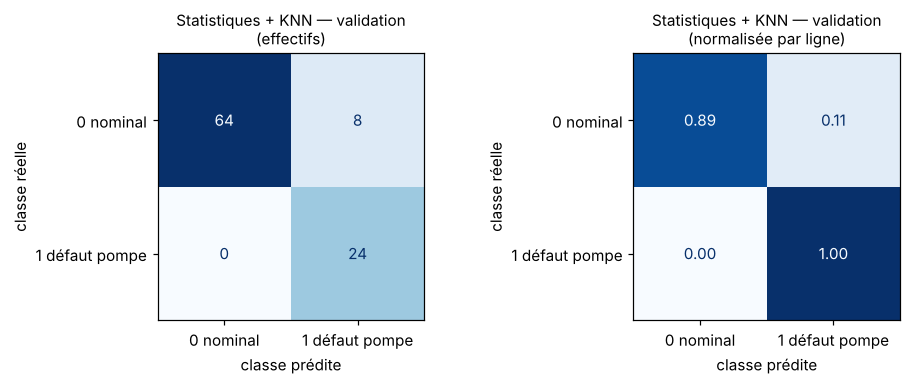

In [23]:
# =============================================================================
# B4.1  Référence : six critères statistiques sur la même tranche, puis KNN (k = 4)
# =============================================================================
NOMS_STAT = ["SD", "RMS", "CF", "SK", "KU", "SF"]

def calcul_criteres_statistiques(signal):
    """SD, RMS, CF (facteur de dégagement), SK, KU (non excès), SF ; moments de dénominateur M."""
    S = np.asarray(signal, dtype=float)
    d = S - S.mean()                                  # écarts centrés
    SD = np.sqrt(np.mean(d ** 2))
    RMS = np.sqrt(np.mean(S ** 2))
    A = np.mean(np.sqrt(np.abs(S)))                   # moyenne des racines des amplitudes
    B = np.mean(np.abs(S))                            # amplitude absolue moyenne
    with np.errstate(divide="ignore", invalid="ignore"):   # dénominateur nul -> nan (jamais 0)
        CF = np.max(np.abs(S)) / A ** 2
        SK = np.mean(d ** 3) / SD ** 3
        KU = np.mean(d ** 4) / SD ** 4
        SF = RMS / B
    return np.array([SD, RMS, CF, SK, KU, SF])

X_train_stat = np.vstack([calcul_criteres_statistiques(x) for x in X_train_cond])   # (384, 6)
X_test_stat  = np.vstack([calcul_criteres_statistiques(x) for x in X_test_cond])    # (96, 6)
assert np.isfinite(X_train_stat).all() and np.isfinite(X_test_stat).all(), "critère indéfini"

model_KNN_stat = nouveau_knn().fit(X_train_stat, Y_train)
pred_train_S = model_KNN_stat.predict(X_train_stat)
pred_test_S  = model_KNN_stat.predict(X_test_stat)
C_test_S, C_test_S_norm = matrices_confusion(Y_test, pred_test_S)

resume_stat = pd.DataFrame(X_train_stat, columns=NOMS_STAT).describe().loc[["mean", "std", "min", "max"]]
part_variance = 100 * X_train_stat.var(axis=0) / X_train_stat.var(axis=0).sum()
resume_stat.loc["part de la variance totale (%)"] = part_variance
display(resume_stat)
dominant = NOMS_STAT[int(np.argmax(part_variance))]
md(f"Sans mise à l'échelle, **{dominant}** porte {fr(part_variance.max())} % de la variance totale des six "
   f"critères bruts : c'est lui qui pèse le plus dans la distance euclidienne de cette référence.")
tracer_matrices(Y_test, pred_test_S, "Statistiques + KNN — validation")

In [24]:
# =============================================================================
# B4.2  Tableau comparatif : statistiques + KNN, RWE + KNN, RWE + ACP(3) + KNN
# =============================================================================
modeles = {
    "Statistiques (6) + KNN": (X_train_stat.shape[1], pred_train_S, pred_test_S),
    "A : RWE (5) + KNN": (X_train.shape[1], pred_train_A, pred_test_A),
    "B : RWE + ACP(3) + KNN": (X_train_reduit.shape[1], pred_train_B, pred_test_B),
}
lignes = []
for jeu, y in [("validation", Y_test), ("apprentissage", Y_train)]:
    for nom, (dim, p_app, p_val) in modeles.items():
        t = taux_depuis_matrice(confusion_matrix(y, p_val if jeu == "validation" else p_app, labels=[0, 1]))
        lignes.append({"jeu": jeu, "représentation": nom, "dimension": dim,
                       "exactitude (%)": 100 * t["Acc"], "exactitude équilibrée (%)": 100 * t["BA"],
                       "rappel défaut (%)": 100 * t["R_D"], "fausses alarmes (%)": 100 * t["F_A"],
                       "FP": t["FP"], "FN": t["FN"]})
tableau_comparatif = pd.DataFrame(lignes).set_index(["jeu", "représentation"]).round(2)
tableau_comparatif

dimension  exactitude (%)  exactitude équilibrée (%)  rappel défaut (%)  fausses alarmes (%)  FP  FN
jeu           représentation                                                                                                              
validation    Statistiques (6) + KNN          6           91.67                      94.44             100.00                11.11   8   0
              A : RWE (5) + KNN               5          100.00                     100.00             100.00                 0.00   0   0
              B : RWE + ACP(3) + KNN          3          100.00                     100.00             100.00                 0.00   0   0
apprentissage Statistiques (6) + KNN          6           96.88                      94.10              88.54                 0.35   1  11
              A : RWE (5) + KNN               5           98.70                      98.09              96.88                 0.69   2   3
              B : RWE + ACP(3) + KNN          3           98.18                      97.05              94.79                 0.69   2   5

In [25]:
# =============================================================================
# B4.3  Indices de validation où A et B divergent : quelle prédiction est correcte ?
# =============================================================================
idx_diff = np.flatnonzero(pred_test_A != pred_test_B)
part_A = model_KNN.predict_proba(X_test)[:, 1]                 # part de voisins « défaut » (A)
part_B = model_KNN_reduit.predict_proba(X_test_reduit)[:, 1]   # idem pour B

desaccords = pd.DataFrame({
    "indice validation": idx_diff,
    "classe réelle": Y_test[idx_diff],
    "prédiction A": pred_test_A[idx_diff],
    "votes défaut A (/4)": np.rint(K_VOISINS * part_A[idx_diff]).astype(int),
    "prédiction B": pred_test_B[idx_diff],
    "votes défaut B (/4)": np.rint(K_VOISINS * part_B[idx_diff]).astype(int),
})
desaccords["prédiction correcte"] = np.where(desaccords["prédiction A"] == desaccords["classe réelle"], "A", "B")
n_diff = idx_diff.size
n_A_juste = int((desaccords["prédiction correcte"] == "A").sum())
n_B_juste = n_diff - n_A_juste
erreurs_communes = int(np.sum((pred_test_A != Y_test) & (pred_test_B != Y_test)))
n_diff_SA = int(np.sum(pred_test_S != pred_test_A))

if n_diff:
    display(desaccords.set_index("indice validation"))
md(f"- Prédictions de validation différentes entre A et B : **{n_diff}** sur {len(Y_test)}"
   + (f" (indices {idx_diff.tolist()}) ; A a raison **{n_A_juste}** fois, B **{n_B_juste}** fois." if n_diff else
      " : les deux modèles décident de la même façon sur ces lignes.")
   + f"\n- Fenêtres mal classées par A **et** par B : **{erreurs_communes}** ; prédictions différentes entre la "
     f"référence statistique et A : **{n_diff_SA}**.")

- Prédictions de validation différentes entre A et B : **0** sur 96 : les deux modèles décident de la même façon sur ces lignes.
- Fenêtres mal classées par A **et** par B : **0** ; prédictions différentes entre la référence statistique et A : **8**.

In [26]:
# =============================================================================
# B4.4  Exemple détaillé : les 4 voisins d'une fenêtre divergente dans les espaces A et B
# =============================================================================
if n_diff:
    i0 = int(idx_diff[0])
    dist_A, vois_A = model_KNN.kneighbors(X_test[[i0]])            # 4 voisins dans l'espace RWE
    dist_B, vois_B = model_KNN_reduit.kneighbors(X_test_reduit[[i0]])   # 4 voisins dans CP1–CP3
    vois_A, vois_B, dist_A, dist_B = vois_A[0], vois_B[0], dist_A[0], dist_B[0]
    sigma_CP4 = X_train_ACP[:, 3].std()

    def ecart_CP4(indices):
        """Écart |CP4(voisin) − CP4(fenêtre)|, en écarts-types d'apprentissage de CP4."""
        return np.abs(X_train_ACP[indices, 3] - X_test_ACP[i0, 3]) / sigma_CP4

    display(pd.DataFrame({
        "voisin A (indice app.)": vois_A, "classe A": Y_train[vois_A], "distance A": dist_A,
        "écart CP4 A (σ)": ecart_CP4(vois_A),
        "voisin B (indice app.)": vois_B, "classe B": Y_train[vois_B], "distance B": dist_B,
        "écart CP4 B (σ)": ecart_CP4(vois_B),
    }, index=[f"voisin {r + 1}" for r in range(K_VOISINS)]).round(4))

    perdus = np.array([v for v in vois_A if v not in vois_B])     # voisins de A absents en B
    gagnes = np.array([v for v in vois_B if v not in vois_A])     # voisins apparus en B
    md(f"Fenêtre de validation **{i0}** (classe réelle {Y_test[i0]}) : A prédit {pred_test_A[i0]} "
       f"({int(round(K_VOISINS * part_A[i0]))}/4 votes défaut), B prédit {pred_test_B[i0]} "
       f"({int(round(K_VOISINS * part_B[i0]))}/4). Voisin(s) perdu(s) par B : {perdus.tolist()} "
       f"(classes {Y_train[perdus].tolist()}, écart CP4 {[fr(e) for e in ecart_CP4(perdus)]} σ) ; "
       f"voisin(s) gagné(s) : {gagnes.tolist()} (classes {Y_train[gagnes].tolist()}, "
       f"écart CP4 {[fr(e) for e in ecart_CP4(gagnes)]} σ). "
       + r"Comme $d_A^2 = d_B^2 + \Delta_{4}^2$ (la CP5 étant nulle), tout voisin gagné par B est au moins "
         r"aussi éloigné selon CP4 que tout voisin perdu : c'est la suppression de CP4 qui modifie le "
         r"voisinage, donc le vote.")
else:
    print("Aucune divergence A/B sur la validation : pas d'exemple à détailler.")

Aucune divergence A/B sur la validation : pas d'exemple à détailler.


In [27]:
# =============================================================================
# B4.5  Erreurs et coûts opérationnels (pondération ILLUSTRATIVE, pas une donnée du banc)
# =============================================================================
COUT_FP, COUT_FN = 1.0, 10.0      # hypothèse pédagogique : un défaut manqué coûte 10 fausses alarmes
couts = {}
for nom, (_, _, p_val) in modeles.items():
    t = taux_depuis_matrice(confusion_matrix(Y_test, p_val, labels=[0, 1]))
    couts[nom] = {"FP (fausses alarmes)": t["FP"], "FN (défauts manqués)": t["FN"],
                  "coût = 1·FP + 10·FN": COUT_FP * t["FP"] + COUT_FN * t["FN"]}
pd.DataFrame.from_dict(couts, orient="index")

,FP (fausses alarmes),FN (défauts manqués),coût = 1·FP + 10·FN
Statistiques (6) + KNN,8,0,8.0
A : RWE (5) + KNN,0,0,0.0
B : RWE + ACP(3) + KNN,0,0,0.0


**Lecture de B4.**

- **Des scores identiques n'impliquent pas des prédictions identiques** : deux modèles peuvent avoir la même exactitude en se trompant sur des fenêtres différentes ; d'où la liste des indices divergents.
- **Même si A et B décidaient de la même façon** sur ces 96 lignes, cela ne prouverait pas leur équivalence sur des données futures.
- **Coûts opérationnels.** Un défaut de pompe manqué (FN) peut laisser l'empilement fonctionner avec une alimentation en eau dégradée (assèchement, échauffement, vieillissement accéléré) ; une fausse alarme (FP) coûte un arrêt ou une inspection inutile. La pondération 1/10 ci-dessus est une hypothèse d'illustration : le classement des représentations peut changer avec ce rapport, il faut donc comparer les erreurs à leurs coûts réels, pas seulement aux pourcentages globaux.

> **Portée de la validation.** Ces fenêtres de validation ont été examinées au fil des sessions 4, 5 et 7. Elles permettent une comparaison pédagogique contrôlée, pas une nouvelle estimation indépendante après des choix de méthodes répétés. Avant déploiement : campagne réservée jamais consultée, séparation par essai ou par système lorsque ces identifiants existent.

## 10. B5 — Invariants et sensibilité

### B5a — Contrôles numériques

1. **Gain global non nul** $g$ : chaque détail est multiplié par $g$, chaque énergie par $g^2$ ; le rapport $r_j$ ne change pas. Gain nul : $0/0$, RWE indéfinie.
2. **ACP complète non blanchie** : rotation des coordonnées centrées, donc distances conservées et KNN inchangé. Le blanchiment diviserait chaque score par $\sqrt{\lambda_j}$ : distances modifiées, et $\lambda_5 \approx 0$ ferait exploser le bruit d'arrondi.
3. **Permutation commune des colonnes** (apprentissage *et* validation) : la distance euclidienne ne dépend pas de l'ordre des coordonnées, et l'ACP de données permutées donne les mêmes valeurs propres et les mêmes scores au signe près : prédictions inchangées.
4. **Permutation appliquée à la seule validation** : les colonnes ne correspondent plus aux mêmes détails (par exemple D1 d'un côté, D3 de l'autre). Les dimensions restent correctes, **aucune erreur n'est levée**, mais les distances n'ont plus de sens : c'est une panne silencieuse du pipeline.

In [28]:
# =============================================================================
# B5a.1  Invariance des RWE à un gain global non nul (et cas du gain nul)
# =============================================================================
for g in [2.0, -0.5, 1000.0]:
    ecart = max(np.abs(extraire_RWE(g * x) - X_train[i]).max() for i, x in enumerate(X_train_cond))
    print(f"gain g = {g:>7}: max |RWE(g·x) − RWE(x)| sur les 384 fenêtres = {ecart:.2e}")
try:
    extraire_RWE(0.0 * X_train_cond[0])
except ValueError as erreur:
    print("gain g =       0: ValueError ->", erreur)

# Complément : décalage constant (offset). Avec l'extension symétrique, les détails d'une constante
# sont nuls : la RWE ignore aussi le niveau moyen (information du point de fonctionnement perdue).
ecart_offset = max(np.abs(extraire_RWE(x + 10.0) - X_train[i]).max() for i, x in enumerate(X_train_cond))
print(f"décalage +10 : max |RWE(x + 10) − RWE(x)| = {ecart_offset:.2e}")

gain g =     2.0: max |RWE(g·x) − RWE(x)| sur les 384 fenêtres = 0.00e+00
gain g =    -0.5: max |RWE(g·x) − RWE(x)| sur les 384 fenêtres = 0.00e+00


gain g =  1000.0: max |RWE(g·x) − RWE(x)| sur les 384 fenêtres = 1.71e-13
gain g =       0: ValueError -> énergie des détails nulle : RWE indéfinie
décalage +10 : max |RWE(x + 10) − RWE(x)| = 3.34e-13


In [29]:
# =============================================================================
# B5a.2  Conservation des distances par l'ACP complète non blanchie
# =============================================================================
d_X  = pairwise_distances(X_test, X_train)                           # distances utilisées par le KNN A
d_Z5 = pairwise_distances(X_test_ACP, X_train_ACP)                   # ACP complète (5 scores)
d_Z4 = pairwise_distances(X_test_ACP[:, :4], X_train_ACP[:, :4])     # 4 scores
d_Z3 = pairwise_distances(X_test_reduit, X_train_reduit)             # 3 scores (branche B)

print(f"ACP complète : max |d_Z − d_X| = {np.abs(d_Z5 - d_X).max():.2e}")
print(f"4 scores     : max |d_Z − d_X| = {np.abs(d_Z4 - d_X).max():.2e}   "
      f"(max |CP5| app./val. = {np.abs(X_train_ACP[:, 4]).max():.1e} / {np.abs(X_test_ACP[:, 4]).max():.1e})")
rapport = d_Z3[d_X > 0] / d_X[d_X > 0]
print(f"3 scores     : d_Z3/d_X médian = {np.median(rapport):.4f}, minimum = {rapport.min():.4f} "
      f"(projection : les distances ne peuvent que diminuer)")

pred_test_complete = nouveau_knn().fit(X_train_ACP, Y_train).predict(X_test_ACP)
print("KNN sur les 5 scores : prédictions identiques à A ?", np.array_equal(pred_test_complete, pred_test_A))

lam5 = model_ACP.explained_variance_[-1]
if lam5 > 0:
    print(f"Blanchiment : λ5 = {lam5:.2e} -> le score CP5 (bruit d'arrondi) serait multiplié par "
          f"1/√λ5 = {1 / np.sqrt(lam5):.2e}")
else:
    print("Blanchiment : λ5 = 0 exactement -> division par zéro, le blanchiment de CP5 est indéfini")

ACP complète : max |d_Z − d_X| = 2.26e-14
4 scores     : max |d_Z − d_X| = 2.26e-14   (max |CP5| app./val. = 2.0e-14 / 2.1e-14)
3 scores     : d_Z3/d_X médian = 0.9997, minimum = 0.2422 (projection : les distances ne peuvent que diminuer)
KNN sur les 5 scores : prédictions identiques à A ? True
Blanchiment : λ5 = 1.09e-16 -> le score CP5 (bruit d'arrondi) serait multiplié par 1/√λ5 = 9.58e+07


In [30]:
# =============================================================================
# B5a.3  Permutation des colonnes : commune aux deux jeux, puis validation seule
# =============================================================================
perm = np.array([2, 4, 0, 3, 1])           # permutation arbitraire des colonnes D1..D5

# (a) permutation COMMUNE : on réapprend tout sur les colonnes permutées
X_train_p, X_test_p = X_train[:, perm], X_test[:, perm]
pred_A_commune = nouveau_knn().fit(X_train_p, Y_train).predict(X_test_p)
acp_p = PCA().fit(X_train_p)
pred_B_commune = nouveau_knn().fit(acp_p.transform(X_train_p)[:, :3], Y_train).predict(acp_p.transform(X_test_p)[:, :3])
print("(a) commune  : valeurs propres identiques ?", np.allclose(acp_p.explained_variance_, model_ACP.explained_variance_),
      "| A inchangé ?", np.array_equal(pred_A_commune, pred_test_A),
      "| B inchangé ?", np.array_equal(pred_B_commune, pred_test_B))

# (b) permutation de la SEULE validation, modèles d'apprentissage inchangés
pred_A_val = model_KNN.predict(X_test[:, perm])
pred_B_val = model_KNN_reduit.predict(model_ACP.transform(X_test[:, perm])[:, :3])
print("(b) validation seule : dimensions", X_test[:, perm].shape, "-> aucune erreur levée")
md(f"Permutation de la **seule** validation : **{int(np.sum(pred_A_val != pred_test_A))}** prédiction(s) A et "
   f"**{int(np.sum(pred_B_val != pred_test_B))}** prédiction(s) B modifiées sur {len(Y_test)}, sans aucun message d'erreur.")
tableau_taux({"A normal": C_test_A, "A validation permutée": confusion_matrix(Y_test, pred_A_val, labels=[0, 1]),
              "B normal": C_test_B, "B validation permutée": confusion_matrix(Y_test, pred_B_val, labels=[0, 1])})

(a) commune  : valeurs propres identiques ? True | A inchangé ? True | B inchangé ? True
(b) validation seule : dimensions (96, 5) -> aucune erreur levée


Permutation de la **seule** validation : **24** prédiction(s) A et **24** prédiction(s) B modifiées sur 96, sans aucun message d'erreur.

,exactitude (%),exactitude équilibrée (%),rappel défaut R_D (%),fausses alarmes F_A (%),VN,FP,FN,VP
A normal,100.0,100.0,100.0,0.0,72,0,0,24
A validation permutée,75.0,50.0,0.0,0.0,72,0,24,0
B normal,100.0,100.0,100.0,0.0,72,0,0,24
B validation permutée,75.0,50.0,0.0,0.0,72,0,24,0


### Convention source `upcoef` et reconstruction isolée par `waverec`

La comparaison principale A/B garde la convention source `upcoef`. Comme en session 6, on reconstruit aussi chaque bloc de détails **isolé** avec `waverec` (tous les autres blocs mis à zéro, puis recadrage aux 961 premiers points) sur une fenêtre d'apprentissage. Les écarts éventuels viennent des conventions de **synthèse et de recadrage** : ce n'est ni un défaut physique, ni automatiquement un gain de performance.

,max |upcoef − waverec|,décalage d'alignement (points),E_j upcoef,E_j waverec,r_j upcoef (%),r_j waverec (%)
D1,0.0000,0,0.0003,0.0003,7.6453,7.6449
D2,0.0000,0,0.0004,0.0004,10.8405,10.8401
D3,0.0033,-2,0.0008,0.0008,22.6454,22.6047
D4,0.0024,-2,0.0011,0.0011,34.0867,34.1334
D5,0.0013,-2,0.0008,0.0008,24.7821,24.7770


Reconstruction x − (A5 + ΣD_j) : upcoef 4.19e-03 | waverec 3.84e-16


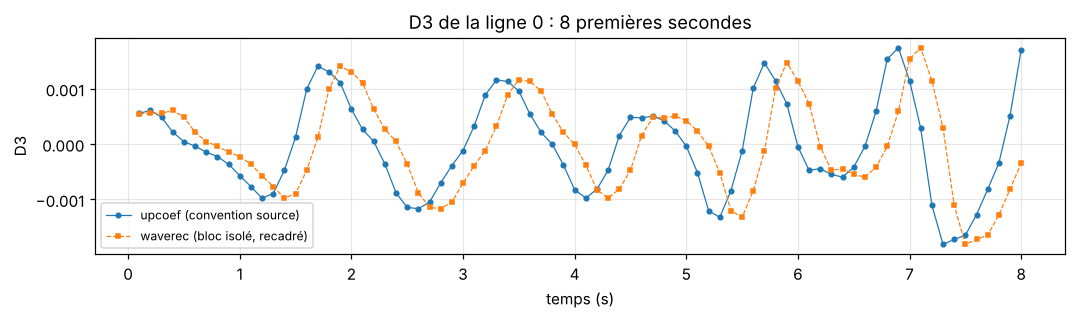

In [31]:
# =============================================================================
# B5a.4  upcoef (partie centrale) vs waverec (bloc isolé, recadré) sur une fenêtre
# =============================================================================
x0 = X_train_cond[i_nom]
coeffs0 = pywt.wavedec(x0, ONDELETTE, level=NIVEAU)

def bloc_isole_waverec(coeffs, position, n):
    """Reconstruit le seul bloc `position` (autres blocs mis à zéro) puis garde les n premiers points."""
    isoles = [c if k == position else np.zeros_like(c) for k, c in enumerate(coeffs)]
    return pywt.waverec(isoles, ONDELETTE)[:n]

D_up = details_reconstruits(x0)                                                  # D1..D5, convention source
D_wr = np.array([bloc_isole_waverec(coeffs0, NIVEAU + 1 - j, M) for j in range(1, NIVEAU + 1)])
A5_up = pywt.upcoef("a", coeffs0[0], ONDELETTE, level=NIVEAU, take=M)
A5_wr = bloc_isole_waverec(coeffs0, 0, M)

def meilleur_decalage(a, b, max_lag=8):
    """Décalage (en points) qui aligne le mieux b sur a, bords exclus."""
    return min(range(-max_lag, max_lag + 1), key=lambda L: np.abs(np.roll(b, L) - a)[20:-20].max())

E_up, E_wr = np.sum(D_up ** 2, axis=1), np.sum(D_wr ** 2, axis=1)
display(pd.DataFrame({
    "max |upcoef − waverec|": np.abs(D_up - D_wr).max(axis=1),
    "décalage d'alignement (points)": [meilleur_decalage(D_up[j], D_wr[j]) for j in range(NIVEAU)],
    "E_j upcoef": E_up, "E_j waverec": E_wr,
    "r_j upcoef (%)": 100 * E_up / E_up.sum(), "r_j waverec (%)": 100 * E_wr / E_wr.sum(),
}, index=[f"D{j}" for j in range(1, NIVEAU + 1)]))
print(f"Reconstruction x − (A5 + ΣD_j) : upcoef {np.abs(x0 - A5_up - D_up.sum(axis=0)).max():.2e} | "
      f"waverec {np.abs(x0 - A5_wr - D_wr.sum(axis=0)).max():.2e}")

j_aff = int(np.argmax(np.abs(D_up - D_wr).max(axis=1)))       # niveau le plus différent
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(t_cond[:80], D_up[j_aff, :80], "o-", ms=3, lw=0.8, label="upcoef (convention source)")
ax.plot(t_cond[:80], D_wr[j_aff, :80], "s--", ms=3, lw=0.8, label="waverec (bloc isolé, recadré)")
ax.set_title(f"D{j_aff + 1} de la ligne {i_nom} : 8 premières secondes")
ax.set_xlabel("temps (s)")
ax.set_ylabel(f"D{j_aff + 1}")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Lecture de B5a.**

- **Gain** : écarts de l'ordre de $10^{-14}$ (arrondi machine) : la RWE est invariante à tout gain non nul, y compris négatif. Elle perd donc l'amplitude absolue. Le complément montre qu'elle ignore aussi un **décalage constant** (les détails d'une constante sont nuls) : le point de fonctionnement n'entre pas dans les caractéristiques.
- **ACP complète** : distances identiques à l'arrondi machine près (~$10^{-14}$), donc mêmes voisins et mêmes prédictions que A. Avec 4 scores, rien ne change non plus (CP5 ≡ 0). Avec 3 scores, les distances sont raccourcies : c'est la seule source de différence entre A et B. Le blanchiment, lui, diviserait CP5 par $\sqrt{\lambda_5}\approx 0$ : le bruit d'arrondi deviendrait une coordonnée de même poids que les autres (ou une division par zéro).
- **Permutations** : commune, elle ne change rien (même géométrie, sauf égalité numérique exceptionnelle). Sur la seule validation, chaque fenêtre est comparée à l'apprentissage avec des colonnes qui ne désignent plus les mêmes détails : les décisions perdent leur sens physique, même si certaines restent justes par hasard, et aucune erreur n'est signalée. D'où l'intérêt de colonnes **nommées** et d'un ordre déclaré (D1…D5).
- **upcoef / waverec** : pour cette longueur impaire (961), les deux conventions coïncident pour D1 et D2 mais diffèrent de quelques points d'alignement aux niveaux profonds ; les RWE changent légèrement. Seule la reconstruction par `waverec` redonne exactement le signal en sommant A5 et les détails. Ce sont des conventions numériques, pas un phénomène physique ni un gain de performance.

### B5b — Conclusion diagnostique (cinq lignes)

Les nombres ci-dessous sont lus dans les résultats calculés plus haut (texte généré automatiquement, donc toujours cohérent avec l'exécution).

In [32]:
# =============================================================================
# B5b  Conclusion en cinq lignes, construite à partir des résultats
# =============================================================================
tA, tB, tS = (taux_depuis_matrice(C) for C in (C_test_A, C_test_B, C_test_S))
lignes_conclusion = [
    f"1. **Représentation utilisée** : RWE db4 (5 détails D1–D5 reconstruits par `upcoef`, A5 exclue) sur la "
    f"tranche S2-45 de {M} points ; branche B = ACP centrée non blanchie, apprise sur l'apprentissage, "
    f"q = {nbr_composante_conserve} (H₃ = {fr(100 * H[2], 4)} % de la variance), puis KNN k = {K_VOISINS}.",
    f"2. **Erreurs observées (validation, {len(Y_test)} fenêtres)** : A → {tA['FP']} FP et {tA['FN']} FN "
    f"(exactitude équilibrée {fr(100 * tA['BA'])} %) ; B → {tB['FP']} FP et {tB['FN']} FN ({fr(100 * tB['BA'])} %) ; "
    f"référence statistique → {tS['FP']} FP et {tS['FN']} FN ({fr(100 * tS['BA'])} %). "
    + (f"A et B divergent sur {n_diff} fenêtre(s) : A a raison {n_A_juste} fois, B {n_B_juste} fois."
       if n_diff else "A et B prennent exactement les mêmes décisions sur ces fenêtres."),
    f"3. **Information perdue** : la normalisation retire l'amplitude absolue, le niveau moyen et les dérives lentes "
    f"(A5) ainsi que la chronologie dans la fenêtre ; l'ACP(3) retire en plus la CP4 ({fr(100 * eta[3], 4)} % de la "
    f"variance d'apprentissage), la CP5 étant nulle par construction (somme des RWE = 1).",
    "4. **Ambiguïté physique** : une redistribution d'énergie entre bandes est compatible avec un défaut de pompe, "
    "mais aussi avec un changement de consigne, de régulation, de température ou de capteur ; les étiquettes "
    "décrivent l'essai, pas le mécanisme, et cette validation déjà consultée donne une estimation optimiste.",
    "5. **Prochaine mesure ou expérience indépendante** : mesurer simultanément débit et pression d'eau (et "
    "température) sur une campagne réservée, avec des défauts de pompe de sévérité contrôlée et des identifiants "
    "d'essai, puis évaluer **une seule fois** un protocole déclaré à l'avance (ondelette, normalisation et q choisis "
    "par validation croisée interne à l'apprentissage).",
]
md("\n".join(lignes_conclusion))

1. **Représentation utilisée** : RWE db4 (5 détails D1–D5 reconstruits par `upcoef`, A5 exclue) sur la tranche S2-45 de 961 points ; branche B = ACP centrée non blanchie, apprise sur l'apprentissage, q = 3 (H₃ = 99,9514 % de la variance), puis KNN k = 4.
2. **Erreurs observées (validation, 96 fenêtres)** : A → 0 FP et 0 FN (exactitude équilibrée 100,00 %) ; B → 0 FP et 0 FN (100,00 %) ; référence statistique → 8 FP et 0 FN (94,44 %). A et B prennent exactement les mêmes décisions sur ces fenêtres.
3. **Information perdue** : la normalisation retire l'amplitude absolue, le niveau moyen et les dérives lentes (A5) ainsi que la chronologie dans la fenêtre ; l'ACP(3) retire en plus la CP4 (0,0486 % de la variance d'apprentissage), la CP5 étant nulle par construction (somme des RWE = 1).
4. **Ambiguïté physique** : une redistribution d'énergie entre bandes est compatible avec un défaut de pompe, mais aussi avec un changement de consigne, de régulation, de température ou de capteur ; les étiquettes décrivent l'essai, pas le mécanisme, et cette validation déjà consultée donne une estimation optimiste.
5. **Prochaine mesure ou expérience indépendante** : mesurer simultanément débit et pression d'eau (et température) sur une campagne réservée, avec des défauts de pompe de sévérité contrôlée et des identifiants d'essai, puis évaluer **une seule fois** un protocole déclaré à l'avance (ondelette, normalisation et q choisis par validation croisée interne à l'apprentissage).

**Règle de protocole.** Une nouvelle famille d'ondelettes, une autre normalisation ou une autre valeur de $q$ (par exemple $q = 4$, qui conserverait toutes les distances) exigerait un **nouveau protocole d'apprentissage déclaré** — choix par validation croisée interne à l'apprentissage, puis une seule évaluation sur des données réservées — et non des consultations répétées de cette validation.

## 11. B6 — Synthèse et auto-évaluation

### Relations à retenir

$$r_j = E_j\Big/\sum_\ell E_\ell;\qquad \sum_j r_j = 1;\qquad X_c\mathbf{1}_5 = 0;\qquad C = \frac{X_c^TX_c}{n-1};\qquad Z_q = X_cV_q;\qquad H_q = \frac{\sum_{j\le q}\lambda_j}{\sum_\ell\lambda_\ell}.$$

Les ondelettes décrivent le **contenu par échelle**, l'ACP **change les coordonnées**, le KNN **prédit une étiquette** et l'évaluation **compte les erreurs**.

### Quiz de 5 minutes

1. **Pourquoi le rang des RWE centrées est-il au plus quatre ?** Chaque ligne a une somme égale à 1, donc la moyenne aussi, et chaque ligne centrée a une somme nulle : toutes les lignes centrées sont orthogonales à $\mathbf{1}_5$, dans un sous-espace de dimension 4. D'où $\mathrm{rang}(X_c)\le 4$ et $\lambda_5 = 0$ : c'est la normalisation, pas un capteur en panne.
2. **99,90 % de variance impliquent-ils 99,90 % d'exactitude ?** Non. La variance mesure l'étalement géométrique des caractéristiques d'apprentissage, sans étiquettes ; l'exactitude compte des décisions justes sur la validation. Une direction de faible variance peut porter la séparation des classes (contre-exemple de la session 5).
3. **Peut-on apprendre séparément l'ACP sur la validation ?** Non. La validation doit être projetée avec la moyenne et les directions apprises sur l'apprentissage ; une seconde ACP créerait un autre repère (scores non comparables, signes arbitraires) et utiliserait l'information des données d'évaluation (fuite d'information).
4. **Que change la multiplication de toutes les RWE par 100 ?** Les lignes somment à 100 au lieu de 1 : covariance × 10⁴, valeurs propres × 10⁴, scores et distances × 100, mais directions, rapports $\eta_j$ et ordre des voisins inchangés, donc mêmes prédictions **si les deux jeux** sont multipliés. Appliquée à un seul jeu, elle fausserait toutes les distances. (Multiplier le *signal* par 100 ne change pas du tout les RWE : invariance au gain.)
5. **Ces scores réutilisés prouvent-ils la généralisation industrielle ?** Non. La même validation a été consultée au fil des sessions (estimation optimiste), les fenêtres ne sont pas séparées par essai, et le corpus ne couvre qu'un banc, un type de défaut et des conditions non documentées. Il faut une campagne réservée, séparée par essai ou par système, sur d'autres conditions de fonctionnement.

### Auto-évaluation des 5 dernières minutes

| Compétence | Note (0 / 1 / 2) | Trace dans le notebook | Notion à reprendre |
|---|---|---|---|
| Produire les RWE | 2 | A3.1 à A3.4 (fonction, assertions, tableaux, graphiques) | Ordre `wavedec` (D5→D1) et permutation déclarée |
| Appliquer la même ACP à de nouvelles données | 2 | B1.2 (`transform` de la validation), B3.1 (contrôle d'alignement) | Signe arbitraire des directions |
| Comparer les erreurs par classe | 2 | A4.2, B3.1, B4.2 à B4.5 | Lien entre erreurs et coûts réels |
| Expliquer une limite | 2 | B4 (portée de la validation), B5a, B5b | Conventions `upcoef` / `waverec` aux bords |

## 12. Analyse complémentaire — point de fonctionnement et séries d'enregistrement

Cette section **prolonge** la fiche (elle n'en fait pas partie) pour préparer le rapport de synthèse. Elle pose une question simple : *qu'est-ce que les classifieurs séparent réellement ?* Trois contrôles sont faits :

1. **C1 — structure du corpus** : niveau moyen du courant de chaque fenêtre et organisation des lignes ;
2. **C2 — signature par régime** : RWE des fenêtres nominales à faible courant, nominales à fort courant et en défaut ;
3. **C3 / C4 — évaluations plus sévères, sur l'apprentissage seul** : validation croisée « une fenêtre exclue » (sans vote pour soi-même), puis « une série exclue ».

Aucun réglage de la comparaison A/B n'est modifié et la validation n'est pas réutilisée pour choisir un paramètre.

In [33]:
# =============================================================================
# C1  Structure du corpus : paliers de courant et séries d'enregistrement
# -----------------------------------------------------------------------------
#  Hypothèse testée : les lignes se répètent par blocs de 12 (9 nominales + 3 défauts).
#  La position d'une ligne dans son bloc (indice modulo 12) désigne alors une « série ».
# =============================================================================
N_SERIES = 12
niveau_train = X_train_cond.mean(axis=1)             # courant moyen de chaque fenêtre (unité d'origine)
niveau_test  = X_test_cond.mean(axis=1)
serie_train = np.arange(len(Y_train)) % N_SERIES     # position dans le bloc de 12
serie_test  = np.arange(len(Y_test))  % N_SERIES
rang = np.arange(len(Y_train) // N_SERIES)           # rang du bloc : 0 à 31

lignes = []
for s in range(N_SERIES):
    a, v = niveau_train[serie_train == s], niveau_test[serie_test == s]
    classes_serie = np.unique(np.r_[Y_train[serie_train == s], Y_test[serie_test == s]])
    assert classes_serie.size == 1, "une série contient deux classes : hypothèse des blocs de 12 fausse"
    lignes.append({"série": s + 1, "classe": int(classes_serie[0]),
                   "fenêtres app. / val.": f"{a.size} / {v.size}",
                   "courant moyen, apprentissage (1re → dernière)": f"{a[0]:.2f} → {a[-1]:.2f}",
                   "courant moyen, validation (1re → dernière)": f"{v[0]:.2f} → {v[-1]:.2f}",
                   "corrélation niveau / rang du bloc": round(float(np.corrcoef(rang, a)[0, 1]), 2),
                   "SD médiane": round(float(np.median(X_train_stat[serie_train == s, 0])), 3)})
tableau_series = pd.DataFrame(lignes).set_index("série")
display(tableau_series)

SEUIL_FORT = 60.0     # limite descriptive : aucune fenêtre entre 49,3 et 61,0 (voir tableau)
fort_train, fort_test = niveau_train > SEUIL_FORT, niveau_test > SEUIL_FORT
md(f"- Chaque position dans le bloc de 12 contient **une seule classe** et un niveau de courant propre : "
   f"le corpus se comporte comme **12 séries** (9 nominales, 3 en défaut) découpées en fenêtres.\n"
   f"- Le niveau de la plupart des séries dérive de façon monotone au fil des blocs, et la validation "
   f"**prolonge** l'apprentissage (ex. série 9 : fin d'apprentissage {fr(niveau_train[serie_train == 8][-1])}, "
   f"début de validation {fr(niveau_test[serie_test == 8][0])}) : ce sont très probablement les mêmes "
   f"enregistrements, donc pas des essais indépendants.\n"
   f"- Tous les défauts sont à fort courant ({fr(niveau_train[Y_train == 1].min(), 1)} à "
   f"{fr(niveau_train[Y_train == 1].max(), 1)}) ; {int(np.sum(~fort_train & (Y_train == 0)))} fenêtres nominales "
   f"sur {int(np.sum(Y_train == 0))} sont à courant plus faible (≤ {fr(niveau_train[~fort_train].max(), 1)}). "
   f"Une seule série nominale ({int(np.sum(fort_train & (Y_train == 0)))} fenêtres) partage le régime des défauts.")

,classe,fenêtres app. / val.,"courant moyen, apprentissage (1re → dernière)","courant moyen, validation (1re → dernière)",corrélation niveau / rang du bloc,SD médiane
série,,,,,,
1,0,32 / 8,0.35 → 0.35,0.35 → 0.35,1.00,0.003
2,0,32 / 8,3.03 → 3.01,3.01 → 3.01,-0.99,0.010
3,0,32 / 8,9.63 → 9.63,9.63 → 9.63,0.61,0.004
4,0,32 / 8,0.33 → 0.33,0.33 → 0.33,-0.34,0.003
5,0,32 / 8,14.49 → 14.65,14.66 → 14.68,1.00,0.069
6,0,32 / 8,21.49 → 22.06,22.08 → 22.17,1.00,0.237
7,0,32 / 8,32.02 → 33.52,33.55 → 33.78,1.00,0.627
8,0,32 / 8,46.40 → 48.77,48.84 → 49.27,1.00,1.148
9,0,32 / 8,61.03 → 63.57,63.63 → 64.02,1.00,1.190


- Chaque position dans le bloc de 12 contient **une seule classe** et un niveau de courant propre : le corpus se comporte comme **12 séries** (9 nominales, 3 en défaut) découpées en fenêtres.
- Le niveau de la plupart des séries dérive de façon monotone au fil des blocs, et la validation **prolonge** l'apprentissage (ex. série 9 : fin d'apprentissage 63,57, début de validation 63,63) : ce sont très probablement les mêmes enregistrements, donc pas des essais indépendants.
- Tous les défauts sont à fort courant (61,8 à 79,6) ; 256 fenêtres nominales sur 288 sont à courant plus faible (≤ 48,8). Une seule série nominale (32 fenêtres) partage le régime des défauts.

RWE moyenne ± écart-type par groupe (apprentissage, en %) :


,r1 (D1),r2 (D2),r3 (D3),r4 (D4),r5 (D5)
"nominal, faible courant (n = 256)",4.72 ± 3.24,6.81 ± 4.84,17.44 ± 7.92,27.63 ± 5.80,43.40 ± 18.13
"nominal, fort courant (n = 32)",4.31 ± 0.17,15.28 ± 0.65,64.30 ± 1.61,5.98 ± 0.56,10.14 ± 2.20
défaut pompe (n = 96),4.98 ± 0.27,17.95 ± 1.54,64.16 ± 3.42,4.31 ± 0.65,8.60 ± 3.50


Pouvoir de séparation À RÉGIME COMPARABLE (|d′| grand = groupes bien séparés) :


,d′ entre nominal fort courant et défaut,part de variance (%)
r1 (D1),-2.94,NaN
r2 (D2),-2.26,NaN
r3 (D3),0.05,NaN
r4 (D4),2.76,NaN
r5 (D5),0.53,NaN
score CP1,-0.49,88.08
score CP2,-0.22,11.03
score CP3,-2.24,0.84
score CP4,1.05,0.05


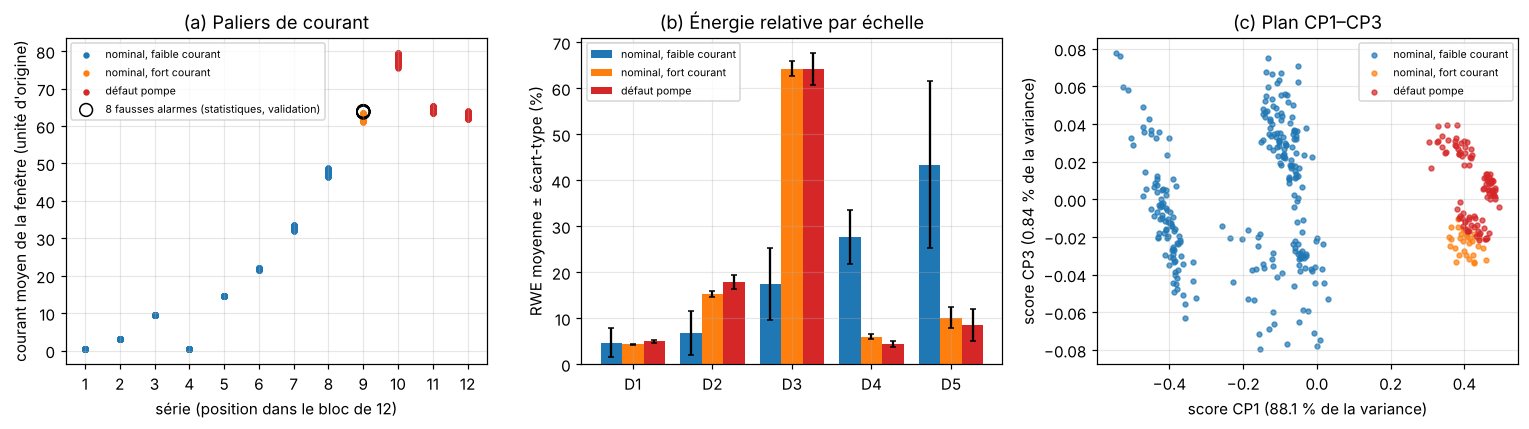

- **La concentration d'énergie dans D3 n'est pas la signature du défaut** : à fort courant, les fenêtres nominales ont 64,3 % d'énergie dans D3, les défauts 64,2 % (d′ = 0,05). C'est la signature du **régime**.
- À régime comparable, le défaut se distingue par un léger transfert vers les échelles rapides : D1 et D2 augmentent, D4 diminue (|d′| de 2,3 à 2,9).
- Dans l'espace de l'ACP, cette séparation est portée par la **CP3** (d′ = -2,24, 0,84 % de la variance) et non par CP1–CP2 (99,1 % de la variance, |d′| ≤ 0,49), qui décrivent surtout le point de fonctionnement.
- Les 8 fausses alarmes de la référence statistique sont les fenêtres nominales de validation à fort courant (niveau 63,6 à 64,0) : dominée par le RMS, cette référence décide surtout d'après le **niveau** du courant.

In [34]:
# =============================================================================
# C2  Signature par régime : nominal faible courant / nominal fort courant / défaut
# =============================================================================
GROUPES = {"nominal, faible courant": ~fort_train & (Y_train == 0),
           "nominal, fort courant":   fort_train & (Y_train == 0),
           "défaut pompe":            Y_train == 1}
COUL_GROUPES = {"nominal, faible courant": "tab:blue", "nominal, fort courant": "tab:orange", "défaut pompe": "tab:red"}

def d_prime(a, b):
    """Écart standardisé entre deux groupes : (moyenne_a − moyenne_b) / écart-type moyen."""
    return (a.mean() - b.mean()) / np.sqrt((a.var() + b.var()) / 2)

resume = {}
for nom, masque in GROUPES.items():
    resume[f"{nom} (n = {int(masque.sum())})"] = [f"{100 * X_train[masque, j].mean():.2f} ± {100 * X_train[masque, j].std():.2f}"
                                                  for j in range(NIVEAU)]
tableau_groupes = pd.DataFrame(resume, index=NOMS_RWE).T
print("RWE moyenne ± écart-type par groupe (apprentissage, en %) :")
display(tableau_groupes)

nf, df_ = GROUPES["nominal, fort courant"], GROUPES["défaut pompe"]
separation = pd.DataFrame({
    "d′ entre nominal fort courant et défaut": [d_prime(X_train[nf, j], X_train[df_, j]) for j in range(NIVEAU)]
                                               + [d_prime(X_train_ACP[nf, j], X_train_ACP[df_, j]) for j in range(4)],
    "part de variance (%)": [np.nan] * NIVEAU + list(100 * eta[:4]),
}, index=NOMS_RWE + [f"score CP{j}" for j in range(1, 5)]).round(2)
print("Pouvoir de séparation À RÉGIME COMPARABLE (|d′| grand = groupes bien séparés) :")
display(separation)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
# (a) niveau de courant par série ; cercles noirs = fausses alarmes de la référence statistique
for nom, masque in GROUPES.items():
    axes[0].scatter(serie_train[masque] + 1, niveau_train[masque], s=10, color=COUL_GROUPES[nom], label=nom)
fp_stat = np.flatnonzero((pred_test_S == 1) & (Y_test == 0))
axes[0].scatter(serie_test[fp_stat] + 1, niveau_test[fp_stat], s=70, facecolors="none", edgecolors="k",
                label=f"{fp_stat.size} fausses alarmes (statistiques, validation)")
axes[0].set_xticks(range(1, N_SERIES + 1))
axes[0].set_xlabel("série (position dans le bloc de 12)")
axes[0].set_ylabel("courant moyen de la fenêtre (unité d'origine)")
axes[0].set_title("(a) Paliers de courant")
axes[0].legend(fontsize=7)
# (b) RWE par groupe
largeur = 0.27
for k, (nom, masque) in enumerate(GROUPES.items()):
    axes[1].bar(np.arange(1, NIVEAU + 1) + (k - 1) * largeur, 100 * X_train[masque].mean(axis=0), largeur,
                yerr=100 * X_train[masque].std(axis=0), capsize=2, color=COUL_GROUPES[nom], label=nom)
axes[1].set_xticks(range(1, NIVEAU + 1), [f"D{j}" for j in range(1, NIVEAU + 1)])
axes[1].set_ylabel("RWE moyenne ± écart-type (%)")
axes[1].set_title("(b) Énergie relative par échelle")
axes[1].legend(fontsize=7)
# (c) plan CP1–CP3
for nom, masque in GROUPES.items():
    axes[2].scatter(X_train_ACP[masque, 0], X_train_ACP[masque, 2], s=10, alpha=0.7, color=COUL_GROUPES[nom], label=nom)
axes[2].set_xlabel(f"score CP1 ({100 * eta[0]:.1f} % de la variance)")
axes[2].set_ylabel(f"score CP3 ({100 * eta[2]:.2f} % de la variance)")
axes[2].set_title("(c) Plan CP1–CP3")
axes[2].legend(fontsize=7)
plt.tight_layout()
plt.show()

md(f"- **La concentration d'énergie dans D3 n'est pas la signature du défaut** : à fort courant, les fenêtres "
   f"nominales ont {fr(100 * X_train[nf, 2].mean(), 1)} % d'énergie dans D3, les défauts "
   f"{fr(100 * X_train[df_, 2].mean(), 1)} % (d′ = {fr(separation.iloc[2, 0])}). C'est la signature du **régime**.\n"
   f"- À régime comparable, le défaut se distingue par un léger transfert vers les échelles rapides : D1 et D2 "
   f"augmentent, D4 diminue (|d′| de {fr(abs(separation.iloc[1, 0]), 1)} à {fr(abs(separation.iloc[0, 0]), 1)}).\n"
   f"- Dans l'espace de l'ACP, cette séparation est portée par la **CP3** (d′ = {fr(separation.iloc[7, 0])}, "
   f"{fr(100 * eta[2])} % de la variance) et non par CP1–CP2 ({fr(100 * (eta[0] + eta[1]), 1)} % de la variance, "
   f"|d′| ≤ {fr(max(abs(separation.iloc[5, 0]), abs(separation.iloc[6, 0])))}), qui décrivent surtout le point de fonctionnement.\n"
   f"- Les {fp_stat.size} fausses alarmes de la référence statistique sont les fenêtres nominales de validation à "
   f"fort courant (niveau {fr(niveau_test[fp_stat].min(), 1)} à {fr(niveau_test[fp_stat].max(), 1)}) : dominée par le "
   f"RMS, cette référence décide surtout d'après le **niveau** du courant.")

In [35]:
# =============================================================================
# C3  Évaluation « une fenêtre exclue » (LOO) sur l'apprentissage, selon la représentation et q
# -----------------------------------------------------------------------------
#  Chaque fenêtre est classée par un modèle appris SANS elle : plus de vote pour soi-même.
#  Pour la branche B, l'ACP est réapprise dans chaque pli (pipeline) : aucune fuite d'information.
# =============================================================================
from sklearn.model_selection import LeaveOneOut, LeaveOneGroupOut, cross_val_predict
from sklearn.pipeline import make_pipeline

candidats = {"Statistiques (6) + KNN": (nouveau_knn(), X_train_stat),
             "A : RWE (5) + KNN": (nouveau_knn(), X_train)}
for q in range(1, 5):
    candidats[f"B : RWE + ACP({q}) + KNN"] = (make_pipeline(PCA(n_components=q), nouveau_knn()), X_train)

pred_loo, lignes = {}, {}
for nom, (estimateur, X_) in candidats.items():
    pred_loo[nom] = cross_val_predict(estimateur, X_, Y_train, cv=LeaveOneOut())
    t = taux_depuis_matrice(confusion_matrix(Y_train, pred_loo[nom], labels=[0, 1]))
    lignes[nom] = {"FP": t["FP"], "FN": t["FN"], "rappel défaut (%)": 100 * t["R_D"],
                   "exactitude équilibrée (%)": 100 * t["BA"],
                   "nominales fort courant justes (/32)": int(np.sum((pred_loo[nom] == 0) & nf)),
                   "nominales faible courant justes (/256)": int(np.sum((pred_loo[nom] == 0) & GROUPES["nominal, faible courant"]))}
tableau_loo = pd.DataFrame.from_dict(lignes, orient="index").round(2)
display(tableau_loo)
md(f"- Sans vote pour soi-même, la hiérarchie est confirmée : statistiques **{lignes['Statistiques (6) + KNN']['FN']}** "
   f"défauts manqués, A **{lignes['A : RWE (5) + KNN']['FN']}**, B (q = 3) **{lignes['B : RWE + ACP(3) + KNN']['FN']}**.\n"
   f"- **Effet de q** : avec q = 2 ({fr(100 * H[1], 1)} % de la variance), {lignes['B : RWE + ACP(2) + KNN']['FN']} défauts "
   f"sont manqués ; il faut la CP3 ({fr(100 * eta[2])} % de la variance) pour retomber à "
   f"{lignes['B : RWE + ACP(3) + KNN']['FN']}. La variance expliquée ne dit donc pas où se trouve l'information utile.\n"
   f"- Toutes les erreurs sont dans le régime à fort courant : les 256 fenêtres nominales à faible courant sont "
   f"toujours bien classées, quelle que soit la représentation.")

,FP,FN,rappel défaut (%),exactitude équilibrée (%),nominales fort courant justes (/32),nominales faible courant justes (/256)
Statistiques (6) + KNN,3,26,72.92,85.94,29,256
A : RWE (5) + KNN,3,6,93.75,96.35,29,256
B : RWE + ACP(1) + KNN,21,28,70.83,81.77,11,256
B : RWE + ACP(2) + KNN,11,25,73.96,85.07,21,256
B : RWE + ACP(3) + KNN,4,6,93.75,96.18,28,256
B : RWE + ACP(4) + KNN,3,6,93.75,96.35,29,256


- Sans vote pour soi-même, la hiérarchie est confirmée : statistiques **26** défauts manqués, A **6**, B (q = 3) **6**.
- **Effet de q** : avec q = 2 (99,1 % de la variance), 25 défauts sont manqués ; il faut la CP3 (0,84 % de la variance) pour retomber à 6. La variance expliquée ne dit donc pas où se trouve l'information utile.
- Toutes les erreurs sont dans le régime à fort courant : les 256 fenêtres nominales à faible courant sont toujours bien classées, quelle que soit la représentation.

In [36]:
# =============================================================================
# C4  Évaluation « une série exclue » et intervalles de confiance des taux de validation
# -----------------------------------------------------------------------------
#  Chaque série est classée par un modèle qui n'a vu AUCUNE fenêtre de cette série :
#  c'est la situation d'un nouvel enregistrement.
# =============================================================================
lignes = {}
for nom in ["Statistiques (6) + KNN", "A : RWE (5) + KNN", "B : RWE + ACP(3) + KNN"]:
    estimateur, X_ = candidats[nom]
    p = cross_val_predict(estimateur, X_, Y_train, cv=LeaveOneGroupOut(), groups=serie_train)
    lignes[nom] = {f"série {s + 1} ({'défaut' if Y_train[serie_train == s][0] else 'nominal'}, "
                   f"≈ {niveau_train[serie_train == s].mean():.0f})": int(np.sum((p == Y_train) & (serie_train == s)))
                   for s in range(N_SERIES)}
tableau_serie_exclue = pd.DataFrame.from_dict(lignes, orient="index")
print("Fenêtres bien classées sur 32 lorsque leur série est absente de l'apprentissage :")
display(tableau_serie_exclue.T)

# D'où viennent les 4 voisins des fenêtres de validation (branche A) ?
_, voisins_val = model_KNN.kneighbors(X_test)
meme_serie = serie_train[voisins_val] == serie_test[:, None]
print(f"Voisins issus de la MÊME série que la fenêtre de validation : {100 * meme_serie.mean():.1f} % "
      f"(fort courant : {100 * meme_serie[fort_test].mean():.1f} %) ; attendu au hasard : {100 / N_SERIES:.1f} %")

# Borne supérieure à 95 % d'un taux d'erreur quand on observe 0 erreur sur n essais : 1 − 0,05^(1/n)
def borne_sup_95(n):
    return 1 - 0.05 ** (1 / n)

n_def_val, n_nom_fort_val = int(np.sum(Y_test == 1)), int(np.sum(fort_test & (Y_test == 0)))
egalites_val = egalites_de_vote(model_KNN, X_test)
print(f"0 défaut manqué sur {n_def_val}  -> taux réel de défauts manqués ≤ {100 * borne_sup_95(n_def_val):.1f} % (95 %)")
print(f"0 fausse alarme sur {n_nom_fort_val} nominales à fort courant -> taux réel ≤ {100 * borne_sup_95(n_nom_fort_val):.1f} % (95 %)")
print(f"Égalités 2–2 en validation (A) : indices {egalites_val.tolist()}, classe réelle {Y_test[egalites_val].tolist()}, "
      f"à fort courant : {fort_test[egalites_val].tolist()}")

s_nf = int(serie_train[nf][0])
cles_A = list(lignes["A : RWE (5) + KNN"])
defauts_justes_A = sum(lignes["A : RWE (5) + KNN"][cles_A[s]] for s in range(N_SERIES) if Y_train[serie_train == s][0] == 1)
md(f"- **Série exclue, côté défauts** : quand une série en défaut est absente de l'apprentissage, la branche A ne "
   f"reconnaît plus que **{defauts_justes_A} fenêtres en défaut sur 96** : un enregistrement en défaut jamais vu est "
   f"mal reconnu.\n"
   f"- **Série exclue, côté nominal** : la série nominale à fort courant (série {s_nf + 1}) est alors classée « défaut » "
   f"dans {32 - lignes['A : RWE (5) + KNN'][cles_A[s_nf]]} cas sur 32. Ce résultat est **attendu** : c'est la seule "
   f"série nominale de ce régime, son exclusion ne laisse aucune référence nominale à fort courant. Il montre surtout "
   f"le manque de données, pas une faiblesse propre aux méthodes.\n"
   f"- {fr(100 * meme_serie[fort_test].mean(), 1)} % des voisins des fenêtres de validation à fort courant viennent de "
   f"leur propre série : le score de validation mesure la continuité d'enregistrements déjà vus, pas une généralisation à un nouvel essai.\n"
   f"- Les 100 % de validation reposent sur {n_def_val} défauts et {n_nom_fort_val} fenêtres nominales réellement "
   f"difficiles : les taux d'erreur réels restent compatibles avec {fr(100 * borne_sup_95(n_def_val), 1)} % de défauts "
   f"manqués et {fr(100 * borne_sup_95(n_nom_fort_val), 1)} % de fausses alarmes dans ce régime.")

Fenêtres bien classées sur 32 lorsque leur série est absente de l'apprentissage :


,Statistiques (6) + KNN,A : RWE (5) + KNN,B : RWE + ACP(3) + KNN
"série 1 (nominal, ≈ 0)",32,32,32
"série 2 (nominal, ≈ 3)",32,32,32
"série 3 (nominal, ≈ 10)",32,32,32
"série 4 (nominal, ≈ 0)",32,32,32
"série 5 (nominal, ≈ 15)",32,32,32
"série 6 (nominal, ≈ 22)",32,32,32
"série 7 (nominal, ≈ 33)",32,32,32
"série 8 (nominal, ≈ 48)",32,32,32
"série 9 (nominal, ≈ 62)",0,0,0
"série 10 (défaut, ≈ 78)",32,32,32


Voisins issus de la MÊME série que la fenêtre de validation : 71.1 % (fort courant : 97.7 %) ; attendu au hasard : 8.3 %
0 défaut manqué sur 24  -> taux réel de défauts manqués ≤ 11.7 % (95 %)
0 fausse alarme sur 8 nominales à fort courant -> taux réel ≤ 31.2 % (95 %)
Égalités 2–2 en validation (A) : indices [32], classe réelle [0], à fort courant : [True]


- **Série exclue, côté défauts** : quand une série en défaut est absente de l'apprentissage, la branche A ne reconnaît plus que **46 fenêtres en défaut sur 96** : un enregistrement en défaut jamais vu est mal reconnu.
- **Série exclue, côté nominal** : la série nominale à fort courant (série 9) est alors classée « défaut » dans 32 cas sur 32. Ce résultat est **attendu** : c'est la seule série nominale de ce régime, son exclusion ne laisse aucune référence nominale à fort courant. Il montre surtout le manque de données, pas une faiblesse propre aux méthodes.
- 97,7 % des voisins des fenêtres de validation à fort courant viennent de leur propre série : le score de validation mesure la continuité d'enregistrements déjà vus, pas une généralisation à un nouvel essai.
- Les 100 % de validation reposent sur 24 défauts et 8 fenêtres nominales réellement difficiles : les taux d'erreur réels restent compatibles avec 11,7 % de défauts manqués et 31,2 % de fausses alarmes dans ce régime.

## 13. Glossaire et références

- **Vecteur de composition** : coordonnées positives ou nulles à somme fixée ; une ligne de RWE est un point d'un simplexe (notation $r$, sans unité).
- **Variance expliquée cumulée** $H_q$ : fraction de la variabilité d'apprentissage conservée par $q$ axes ; distincte de l'exactitude de classification.
- **Fausse alarme / défaut manqué** : nominal prédit en défaut (FP) / défaut prédit nominal (FN).
- **Invariant** : grandeur inchangée par une transformation précisée ; la RWE, invariante au gain, perd l'amplitude absolue.

**Références**

[1] Kim, J. ; Tak, Y. (2014). *Implementation of discrete wavelet transform-based discrimination and state-of-health diagnosis for a polymer electrolyte membrane fuel cell.* International Journal of Hydrogen Energy 39, 10664–10682. doi:10.1016/j.ijhydene.2014.04.205.
[2] Documentation PyWavelets (`wavedec`, `upcoef`, `waverec`) et scikit-learn (`PCA`, `KNeighborsClassifier`, `ConfusionMatrixDisplay`).
[3] Notebooks sources S2-45A Train/Validation et S2-45B Validation, données archivées de la session 4, fiches des sessions 5 à 7 (ENERGY-Lab, Université de La Réunion).

In [37]:
# =============================================================================
# Fin — contrôle d'exécution complète
# =============================================================================
print("Notebook exécuté jusqu'au bout :", datetime.now().strftime("%Y-%m-%d %H:%M"))
print("Toutes les assertions (dimensions, valeurs finies, positivité, sommes, alignement) sont passées.")
print("Rappel : Exécution -> Redémarrer la session et tout exécuter, puis enregistrer Session_7_NOYON.ipynb.")

Notebook exécuté jusqu'au bout : 2026-11-10 10:18
Toutes les assertions (dimensions, valeurs finies, positivité, sommes, alignement) sont passées.
Rappel : Exécution -> Redémarrer la session et tout exécuter, puis enregistrer Session_7_NOYON.ipynb.
